# 📋 Lab 03 (Part 2 of 2): Evaluating Structured Outputs in 2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/03-structured-outputs-part-2-lab.ipynb)

⏱️ ~25 min (Tasks 8–10) · +30 min of challenges

**Previously, in Part 1:**<br>
① 100% schema-valid, yet only 8 of 20 invoices fully right.<br>
② 3 invented values; 2 "model errors" were the answer key's.<br>
③ Now: what can you catch with no labels, and do you ship?

**How this lab works:** ▶️ **Run** (<kbd>Shift</kbd>+<kbd>Enter</kbd>; 🧰 = just run) · ✋ **Your turn** (fill the `...`) · ❓ **Quick check** (pick, run) · 🔑 **Key takeaway**

▶️ **Run** the next five cells: 📦 install · ⚙️ config · 🎨 lab kit · 📦 invoice batch · 🧰 catch-up (rebuilds Part 1).

In [ ]:
%%capture
# jsonschema is the only extra; Colab already ships pydantic v2, pandas and matplotlib.
!pip install -q jsonschema "pydantic>=2"

In [ ]:
# --- Imports -------------------------------------------------------------------------------
import json
import re
from copy import deepcopy
from datetime import date, datetime, timedelta
from decimal import Decimal, ROUND_HALF_UP
from difflib import SequenceMatcher
from importlib.metadata import version
from typing import Literal, Optional

import jsonschema
import matplotlib.pyplot as plt
import pandas as pd
import pydantic
from IPython.display import Markdown, display
from pydantic import BaseModel, ConfigDict, Field, model_validator
from pydantic import ValidationError as PydanticValidationError

# --- Configuration: the ONLY place model IDs live ------------------------------------------
PROVIDER = "mock"                 # "mock" (offline, default) | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"       # current low-cost OpenAI model (Nov 2026)
ANTHROPIC_MODEL = "claude-haiku-5-5"
pd.set_option("display.max_colwidth", 120)

print(f"✅ Imports OK · pydantic {pydantic.VERSION} · jsonschema {version('jsonschema')}")
print(f"🔌 PROVIDER = {PROVIDER!r} → " + ("recorded extractions, no API calls, no keys" if PROVIDER == "mock"
                                         else "LIVE calls: your numbers will differ from the Expected Output blocks"))

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 📦 Invoice batch + helpers (run me; reading the data now spoils Task 7)
# 20 synthetic invoices (fictional vendors). For each one we have:
#   SOURCES[id]       the document text the extractor saw
#   MOCK_OUTPUTS[id]  the extraction it returned, recorded from a strict structured-output run
#   GOLD[id]          the human-labelled answer key
# Plus LEGACY_OUTPUTS: two records from a 2024-style prompt-only JSON pipeline (no constrained decoding).
_NET_DAYS = {"Net 15": 15, "Net 30": 30, "Net 45": 45, "Net 60": 60}
SYMBOL = {"USD": "$", "CAD": "C$", "GBP": "£", "EUR": "€"}


def _money(x):
    return float(Decimal(str(x)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))


def _invoice(num, vendor, address, issued, terms, items, tax_rate, currency="USD", po=None, notes=None):
    due = None
    if terms in _NET_DAYS:
        due = (date.fromisoformat(issued) + timedelta(days=_NET_DAYS[terms])).isoformat()
    lines = [{"description": d, "quantity": q, "unit_price": float(p),
              "line_total": _money(Decimal(str(q)) * Decimal(str(p)))} for d, q, p in items]
    subtotal = _money(sum(Decimal(str(li["line_total"])) for li in lines))
    tax = _money(Decimal(str(subtotal)) * Decimal(str(tax_rate)))
    return {"invoice_number": num, "vendor_name": vendor, "vendor_address": address,
            "invoice_date": issued, "due_date": due, "po_number": po, "currency": currency,
            "line_items": lines, "subtotal": subtotal, "tax_rate": tax_rate, "tax_amount": tax,
            "total_amount": _money(Decimal(str(subtotal)) + Decimal(str(tax))),
            "payment_terms": terms, "notes": notes}


def render_source(inv, date_style="iso", thousands=True, decimal_comma=False, currency_line=True,
                  vendor_upper=False, reverse_items=False):
    """Render an invoice record as the plain-text document an extractor would read."""
    sym = SYMBOL[inv["currency"]]

    def d(iso):
        x = date.fromisoformat(iso)
        return {"iso": iso, "us": x.strftime("%m/%d/%Y"), "dayfirst": x.strftime("%d/%m/%Y")}[date_style]

    def m(v):
        s = f"{v:,.2f}" if thousands else f"{v:.2f}"
        if decimal_comma:
            s = s.translate(str.maketrans({",": ".", ".": ","}))
        return sym + s

    rows = [inv["vendor_name"].upper() if vendor_upper else inv["vendor_name"], inv["vendor_address"], "",
            f"INVOICE  {inv['invoice_number']}", f"Invoice date: {d(inv['invoice_date'])}"]
    if inv["due_date"]:
        rows.append(f"Due date:     {d(inv['due_date'])}")
    if inv["po_number"]:
        rows.append(f"PO number:    {inv['po_number']}")
    rows.append(f"Terms:        {inv['payment_terms']}")
    if currency_line:
        rows.append(f"Currency:     {inv['currency']}")
    rows += ["", f"{'Description':<30}{'Qty':>5}   {'Unit price':>12}  {'Amount':>12}"]
    for li in (inv["line_items"][::-1] if reverse_items else inv["line_items"]):
        rows.append(f"{li['description']:<30}{li['quantity']:>5g} x {m(li['unit_price']):>12}  {m(li['line_total']):>12}")
    rows += ["", f"Subtotal:   {m(inv['subtotal'])}", f"Tax ({inv['tax_rate'] * 100:g}%):  {m(inv['tax_amount'])}",
             f"TOTAL:      {m(inv['total_amount'])}"]
    if inv["notes"]:
        rows.append(f"Notes: {inv['notes']}")
    return "\n".join(rows)


_BATCH = [  # (record, how the document is formatted)
    (_invoice("INV-2026-0101", "Acme Supplies Co.", "123 Main St, Springfield, IL 62704", "2026-03-02", "Net 30",
              [("Widget A", 10, 25), ("Widget B", 5, 40)], 0.08, po="PO-47120"), {}),
    (_invoice("INV-2026-0102", "TechParts Inc.", "456 Oak Ave, Austin, TX 73301", "2026-03-05", "Net 30",
              [("Circuit Board X1", 100, 12.5), ("Connector Pack", 200, 3.75), ("Solder Wire 1kg", 2, 45)], 0.0825,
              notes="Bulk order discount applied"), {}),
    (_invoice("INV-2026-0103", "Global Logistics Ltd.", "88 Harbor Rd, Long Beach, CA 90802", "2026-03-09",
              "Due on receipt", [("Freight Shipping", 1, 1500)], 0.0, notes="Expedited shipping"), {}),
    (_invoice("INV-2026-0104", "TechParts Inc.", "456 Oak Ave, Austin, TX 73301", "2026-03-12", "Net 30",
              [("USB-C Cable", 50, 6.4), ("Power Supply 12V", 20, 18.75)], 0.0825, po="PO-47188"), {}),
    (_invoice("INV-2026-0105", "Steel Works Manufacturing", "321 Industrial Pkwy, Pittsburgh, PA 15201", "2026-02-27",
              "Net 45", [("Steel Plate 4x8", 20, 185), ("Steel Rod 1in", 50, 22)], 0.06, po="PO-47002",
              notes="Delivery to loading dock B"), {}),
    (_invoice("INV-2026-0106", "Brightline Consulting Ltd", "14 Kingsway, London WC2B 6XF, UK", "2026-03-04", "Net 30",
              [("Advisory Services (days)", 3, 950)], 0.20, currency="GBP"), {"date_style": "dayfirst"}),
    (_invoice("INV-2026-0107", "Maple Leaf Print Co.", "200 King St W, Toronto, ON M5H 3T4, Canada", "2026-02-05",
              "Net 30", [("Business Cards (box)", 20, 45), ("Vinyl Banner", 2, 115)], 0.13, currency="CAD"),
     {"currency_line": False}),
    (_invoice("INV-2026-0108", "Cedar Grove Landscaping", "9 Elm Ct, Boulder, CO 80302", "2026-03-11", "Net 30",
              [("Monthly Grounds Maintenance", 1, 640)], 0.0, po="PO-47215", notes="Tax-exempt service"), {}),
    (_invoice("INV-2026-0109", "Pinnacle IT Services", "500 Tech Blvd, Raleigh, NC 27601", "2026-03-13", "Net 30",
              [("Laptop Setup", 8, 75), ("Network Audit", 1, 1200)], 0.0475, po="PO-48213"), {}),
    (_invoice("INV-2026-0110", "Quick Print Shop", "55 Paper St, Portland, OR 97201", "2026-03-16", "Net 15",
              [("Business Cards", 500, 0.1), ("Flyers (100 pack)", 3, 24)], 0.0), {}),
    (_invoice("INV-2026-0111", "CloudServ Pro", "100 Cloud Lane, Seattle, WA 98101", "2026-03-01", "Net 30",
              [("Cloud Hosting (Monthly)", 1, 899), ("SSL Certificate", 1, 49)], 0.0, po="PO-47301",
              notes="Annual renewal"), {}),
    (_invoice("INV-2026-0112", "Lakeside Medical Supply", "77 Shore Dr, Madison, WI 53703", "2026-03-17", "Net 30",
              [("Exam Gloves (case)", 25, 82), ("Hand Sanitizer 1L", 50, 21.7)], 0.055, po="PO-47333"), {}),
    (_invoice("INV-2026-0113", "Summit Office Furniture", "1200 Peak Rd, Denver, CO 80202", "2026-03-18", "Net 60",
              [("Standing Desk", 4, 489), ("Ergonomic Chair", 4, 315)], 0.0815, po="PO-47340"), {}),
    (_invoice("INV-2026-0114", "Blue Harbor Catering", "3 Pier Ave, Charleston, SC 29401", "2026-03-19",
              "Due on receipt", [("Lunch Catering (per person)", 40, 18.5)], 0.09, notes="Event: Q1 all-hands"), {}),
    (_invoice("INV-2026-0115", "Northwind Office Supply", "42 Commerce Way, Columbus, OH 43215", "2026-03-20", "Net 30",
              [("Printer Paper (case)", 10, 32.99), ("Ink Cartridge", 4, 28.5), ("Stapler", 3, 12)], 0.0575,
              po="PO-47402"), {}),
    (_invoice("INV-2026-0116", "Bayside Freight Partners LLC", "900 Dock St, Oakland, CA 94607", "2026-03-23", "Net 30",
              [("LTL Freight", 1, 780), ("Liftgate Fee", 1, 65)], 0.0), {}),
    (_invoice("INV-2026-0117", "Granite Tool & Supply", "15 Quarry Ln, Barre, VT 05641", "2026-03-24", "Net 30",
              [("Drill Bit Set", 12, 45), ("Safety Glasses", 30, 8.25)], 0.06, po="PO-47455"), {}),
    (_invoice("INV-2026-0118", "Orchard Analytics Inc.", "8 Orchard Way, Fresno, CA 93721", "2026-03-25", "Net 30",
              [("Data Pipeline Setup", 1, 1200), ("Dashboard License (seat)", 6, 85)], 0.08, po="PO-47460"), {}),
    (_invoice("INV-2026-0119", "Fernwood Janitorial", "61 Birch St, Burlington, VT 05401", "2026-03-26", "Net 45",
              [("Office Cleaning (monthly)", 1, 1150), ("Carpet Shampoo", 1, 240)], 0.06), {}),
    (_invoice("INV-2026-0120", "Atlas Security Systems", "300 Fortress Rd, Phoenix, AZ 85004", "2026-03-27", "Net 30",
              [("Camera Install", 6, 210), ("Monitoring (annual)", 1, 1800)], 0.086, po="PO-47501"), {}),
]
_TRUTH = {rec["invoice_number"]: rec for rec, _ in _BATCH}
SOURCES = {rec["invoice_number"]: render_source(rec, **style) for rec, style in _BATCH}

# The answer key, as a busy human labeller produced it.
GOLD = deepcopy(_TRUTH)
GOLD["INV-2026-0118"]["total_amount"] = 1864.80
GOLD["INV-2026-0119"]["due_date"] = None

# What the strict-mode extractor returned.
MOCK_OUTPUTS = deepcopy(_TRUTH)
_o = MOCK_OUTPUTS
_o["INV-2026-0102"].update(tax_amount=200.00, total_amount=2290.00)
_o["INV-2026-0103"]["due_date"] = "2026-04-08"
_o["INV-2026-0104"]["vendor_name"] = "TechParts lnc."
_o["INV-2026-0105"]["line_items"][1]["line_total"] = 1200.00
_o["INV-2026-0105"].update(subtotal=4900.00, tax_amount=294.00, total_amount=5194.00)
_o["INV-2026-0106"].update(invoice_date="2026-04-03", due_date="2026-03-04")
_o["INV-2026-0107"]["currency"] = "USD"
_o["INV-2026-0109"]["po_number"] = None
_o["INV-2026-0110"]["po_number"] = "PO-48213"
_o["INV-2026-0112"]["total_amount"] = 3370.43
_o["INV-2026-0115"]["line_items"] = _o["INV-2026-0115"]["line_items"][::-1]
_o["INV-2026-0116"]["vendor_name"] = "Bayside Freight Partners"
_o["INV-2026-0117"]["line_items"][0]["quantity"] = 2

# Two outputs from a 2024-style pipeline: "please answer in JSON", no constrained decoding.
LEGACY_OUTPUTS = {
    "legacy-A": {**deepcopy(_TRUTH["INV-2026-0115"]),
                 "line_items": [{"description": "Printer Paper (case)", "quantity": "10", "unit_price": "32.99",
                                 "line_total": 329.9}]},
    "legacy-B": {**deepcopy(_TRUTH["INV-2026-0110"]),
                 "line_items": "500 business cards at $0.10 each = $50.00", "currency": "US Dollars"},
}


def standin_extract(text):
    """Deterministic stand-in for the model, used ONLY for offline robustness tests (Task 9).
    It parses the document text like a model would read it, with a few realistic weaknesses."""
    def grab(pattern):
        mt = re.search(pattern, text, flags=re.M)
        return mt.group(1).strip() if mt else None

    def num(s):
        if s is None:
            return None
        s = re.sub(r"^[^\d\-]+", "", s)
        try:
            return float(s.replace(",", ""))
        except ValueError:
            return None

    def iso(s):
        if s is None or re.fullmatch(r"\d{4}-\d{2}-\d{2}", s):
            return s
        try:
            return datetime.strptime(s, "%m/%d/%Y").date().isoformat()
        except ValueError:
            return s

    lines = text.splitlines()
    currency = grab(r"^Currency:\s*(\w+)") or ("GBP" if "£" in text else "EUR" if "€" in text else "USD")
    items = [{"description": mt.group(1).strip(), "quantity": float(mt.group(2)),
              "unit_price": num(mt.group(3)), "line_total": num(mt.group(4))}
             for mt in re.finditer(r"^(\S.*?)\s{2,}(\d+(?:\.\d+)?) x\s+(\S+)\s+(\S+)$", text, flags=re.M)]
    rate = grab(r"^Tax \(([\d.]+)%\)")
    return {"invoice_number": grab(r"^INVOICE\s+(\S+)"), "vendor_name": lines[0].strip(),
            "vendor_address": lines[1].strip(), "invoice_date": iso(grab(r"^Invoice date:\s*(\S+)")),
            "due_date": iso(grab(r"^Due date:\s*(\S+)")), "po_number": grab(r"^PO number:\s*(\S+)"),
            "currency": currency, "line_items": items, "subtotal": num(grab(r"^Subtotal:\s*(\S+)")),
            "tax_rate": round(float(rate) / 100, 6) if rate else None,
            "tax_amount": num(grab(r"^Tax \([^)]*\):\s*(\S+)")), "total_amount": num(grab(r"^TOTAL:\s*(\S+)")),
            "payment_terms": grab(r"^Terms:\s*(.+)$"), "notes": grab(r"^Notes:\s*(.+)$")}


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (well-behaved for small n and rates near 0 or 1)."""
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


print(f"📦 Loaded {len(SOURCES)} invoices: source documents, recorded extractions, gold labels "
      f"(+{len(LEGACY_OUTPUTS)} legacy outputs)")

In [ ]:
# @title 🧰 Catch-up: rebuild what Part 1 computed (hidden · 431 lines)
import io as _io, sys as _sys
_real = (_sys.stdout, insight, tiles, display)
_sys.stdout, insight, tiles, display = _io.StringIO(), (lambda *a, **k: None), (lambda *a, **k: None), (lambda *a, **k: None)
try:
    # ── from Part 1 ────────────────────────────────────────────────────────────
    class LineItem(BaseModel):
        model_config = ConfigDict(extra="forbid")
        description: str
        quantity: float
        unit_price: float
        line_total: float


    class Invoice(BaseModel):
        """The extraction schema. Field descriptions are sent to the model as instructions."""
        model_config = ConfigDict(extra="forbid")
        invoice_number: str
        vendor_name: str = Field(description="Legal name exactly as printed")
        vendor_address: str
        invoice_date: str = Field(description="Issue date as YYYY-MM-DD")
        due_date: Optional[str] = Field(description="YYYY-MM-DD, or null if no due date is printed")
        po_number: Optional[str] = Field(description="Purchase-order number, or null if none is printed")
        currency: Literal["USD", "CAD", "GBP", "EUR"]
        line_items: list[LineItem]
        subtotal: float
        tax_rate: float = Field(description="Fraction, e.g. 0.0825 for 8.25%")
        tax_amount: float
        total_amount: float
        payment_terms: str
        notes: Optional[str] = Field(description="Free-text note printed on the invoice, or null")


    EXTRACTION_INSTRUCTIONS = (
        "Extract this invoice into the schema. Copy values exactly as printed. "
        "If a field is not printed on the invoice, return null. Never infer, compute or guess a value."
    )

    # ── from Part 1 ────────────────────────────────────────────────────────────
    def extract_invoice(source_text: str) -> dict:
        """Live extraction with native structured outputs. Not called while PROVIDER == 'mock'."""
        if PROVIDER == "openai":
            from openai import OpenAI
            resp = OpenAI().responses.parse(          # Responses API (recommended for new projects)
                model=OPENAI_MODEL,
                instructions=EXTRACTION_INSTRUCTIONS,
                input=source_text,
                text_format=Invoice,                  # strict structured output: constrained decoding
            )
            if resp.output_parsed is None:            # refusal or incomplete response
                raise RuntimeError("No parsed output (refusal or incomplete response)")
            return resp.output_parsed.model_dump()
        if PROVIDER == "anthropic":
            import anthropic
            resp = anthropic.Anthropic().messages.parse(
                model=ANTHROPIC_MODEL,
                max_tokens=4096,
                system=EXTRACTION_INSTRUCTIONS,
                messages=[{"role": "user", "content": source_text}],
                output_format=Invoice,                # structured outputs; no temperature (HTTP 400 since API 2026-10-21)
            )
            if resp.stop_reason != "end_turn":        # "refusal" or "max_tokens" means no trustworthy record
                raise RuntimeError(f"Extraction stopped early: stop_reason={resp.stop_reason!r}")
            return resp.parsed_output.model_dump()
        raise ValueError(f"Unknown PROVIDER {PROVIDER!r}")

    # ── from Part 1 ────────────────────────────────────────────────────────────
    # 👀 Look at: in mock mode the batch is 20 recorded strict-mode extractions; the schema above is what produced them.
    # --- Build the batch -------------------------------------------------------------------------
    if PROVIDER == "mock":
        outputs = deepcopy(MOCK_OUTPUTS)              # recorded strict-mode responses
    else:
        outputs = {iid: extract_invoice(text) for iid, text in SOURCES.items()}

    FIELDS = list(Invoice.model_fields)
    example_id = "INV-2026-0102"
    print(f"📄 SOURCE DOCUMENT  {example_id}\n" + "─" * 66)
    print(SOURCES[example_id])
    print("\n🤖 EXTRACTION (abridged)\n" + "─" * 66)
    shown = {k: v for k, v in outputs[example_id].items() if k not in ("line_items", "vendor_address")}
    print(json.dumps(shown, indent=1))

    tiles([
        ("Invoices in the batch", len(outputs), "one extraction each", None),
        ("Fields per invoice", len(FIELDS), "incl. a nested line_items list", None),
        ("Gold labels", len(GOLD), "human answer key", None),
        ("Provider", PROVIDER, "offline replay" if PROVIDER == "mock" else "live API", None),
    ])

    # ── from Part 1 ────────────────────────────────────────────────────────────
    DATE = r"^\d{4}-\d{2}-\d{2}$"
    invoice_schema = {
        "type": "object",
        "additionalProperties": False,
        "required": FIELDS,                                   # strict modes require every key (nullable ≠ optional)
        "properties": {
            "invoice_number": {"type": "string", "pattern": r"^INV-\d{4}-\d{4}$"},
            "vendor_name": {"type": "string", "minLength": 1},
            "vendor_address": {"type": "string"},
            "invoice_date": {"type": "string", "pattern": DATE},
            "due_date": {"type": ["string", "null"], "pattern": DATE},
            "po_number": {"type": ["string", "null"]},
            "currency": {"type": "string", "enum": ["USD", "CAD", "GBP", "EUR"]},
            "line_items": {
                "type": "array", "minItems": 1,
                "items": {"type": "object", "additionalProperties": False,
                          "required": ["description", "quantity", "unit_price", "line_total"],
                          "properties": {"description": {"type": "string"},
                                         "quantity": {"type": "number", "minimum": 0},
                                         "unit_price": {"type": "number", "minimum": 0},
                                         "line_total": {"type": "number", "minimum": 0}}}},
            "subtotal": {"type": "number", "minimum": 0},
            "tax_rate": {"type": "number", "minimum": 0, "maximum": 1},
            "tax_amount": {"type": "number", "minimum": 0},
            "total_amount": {"type": "number", "minimum": 0},
            "payment_terms": {"type": "string"},
            "notes": {"type": ["string", "null"]},
        },
    }

    # ── from Part 1 ────────────────────────────────────────────────────────────
    validator = jsonschema.Draft202012Validator(invoice_schema)


    def schema_errors(record):
        """All schema violations for one record, as readable strings (empty list = valid)."""
        return [f"{'.'.join(map(str, e.absolute_path)) or '(root)'}: {e.message}" for e in validator.iter_errors(record)]


    def pydantic_ok(record):
        try:
            Invoice.model_validate(record)
            return True
        except PydanticValidationError:
            return False

    # ── from Part 1 ────────────────────────────────────────────────────────────
    # 👀 Look at: the legacy records fail on TYPES; the strict batch passes with a wrong tax inside it.
    schema_results = {iid: schema_errors(rec) for iid, rec in outputs.items()}
    n_valid = sum(not errs for errs in schema_results.values())
    n_pyd = sum(pydantic_ok(rec) for rec in outputs.values())
    legacy_results = {lid: schema_errors(rec) for lid, rec in LEGACY_OUTPUTS.items()}
    n_legacy_valid = sum(not errs for errs in legacy_results.values())

    print(f"Strict batch: {n_valid}/{len(outputs)} schema-valid · {n_pyd}/{len(outputs)} parse into Invoice")
    for lid, errs in legacy_results.items():
        print(f"\n{lid}: {'✅ valid' if not errs else f'❌ {len(errs)} error(s)'}")
        for e in errs:
            print(f"   → {e[:90]}")

    schema_rate = n_valid / len(outputs)
    tiles([
        ("Strict batch: schema-valid", f"{schema_rate:.0%}", f"{n_valid}/{len(outputs)} records", "good" if schema_rate == 1 else "critical"),
        ("Strict batch: Pydantic parse", f"{n_pyd}/{len(outputs)}", "Invoice.model_validate", "good" if n_pyd == len(outputs) else "critical"),
        ("Legacy prompt-only JSON", f"{n_legacy_valid}/{len(LEGACY_OUTPUTS)}", "no constrained decoding", "critical" if n_legacy_valid < len(LEGACY_OUTPUTS) else "good"),
    ])

    # ── from Part 1 ────────────────────────────────────────────────────────────
    # The reference weights. Ask of every field: "if THIS is wrong, what happens next?"
    field_weights = {
        "invoice_number": 1.0,   # reconciliation key
        "vendor_name": 0.9,      # who gets paid
        "vendor_address": 0.3,   # correspondence
        "invoice_date": 0.8,     # accounting and tax period
        "due_date": 0.6,         # late fees, cash planning
        "po_number": 0.6,        # three-way match with purchasing
        "currency": 1.0,         # same digits, different money
        "line_items": 0.8,       # what was bought: expense coding, audit
        "subtotal": 0.8,         # pre-tax amount
        "tax_rate": 0.7,         # must match the jurisdiction
        "tax_amount": 0.9,       # flows into tax reporting
        "total_amount": 1.0,     # THE number that gets paid
        "payment_terms": 0.4,
        "notes": 0.1,
    }
    CRITICAL_MIN_WEIGHT = 0.8   # 👀 Look at: one wrong field at or above this weight fails the whole record


    CRITICAL = [f for f in FIELDS if field_weights[f] >= CRITICAL_MIN_WEIGHT]
    for f, w in sorted(field_weights.items(), key=lambda kv: -kv[1]):
        print(f"  {f:15s} {w:.1f} {'█' * int(w * 20):20s} {'◀ critical' if f in CRITICAL else ''}")

    crit_share = sum(field_weights[f] for f in CRITICAL) / sum(field_weights.values())
    insight(
        f"{len(CRITICAL)} of {len(FIELDS)} fields are critical, and they carry {crit_share:.0%} of the weight",
        f"Critical: {', '.join(f'`{f}`' for f in CRITICAL)}. From here on a record counts as usable only if **every** "
        "critical field is right: that is the gate, and no weight can replace it.\n"
        "**Rule of thumb:** weight for the dashboard, gate on critical fields, and get the weights from the people who "
        "absorb the errors (finance, tax, support), not from the engineer writing the scorer.",
        kind="numbers",
    )

    # ── from Part 1 ────────────────────────────────────────────────────────────
    MONEY = {"subtotal", "tax_amount", "total_amount"}
    LEGAL_SUFFIXES = {"inc", "llc", "ltd", "co", "corp", "plc", "gmbh"}


    def norm_text(s):
        return " ".join(str(s).casefold().split())


    def norm_name(s):
        words = re.sub(r"[^\w\s&]", " ", str(s).casefold()).split()
        while words and words[-1] in LEGAL_SUFFIXES:
            words.pop()
        return " ".join(words)


    def same_cents(a, b):
        return abs(float(a) - float(b)) < 0.005 + 1e-9


    def line_items_match(pred, gold):
        if not isinstance(pred, list) or len(pred) != len(gold):
            return False
        key = lambda li: norm_text(li["description"])
        return all(key(p) == key(g) and all(same_cents(p[k], g[k]) for k in ("quantity", "unit_price", "line_total"))
                   for p, g in zip(sorted(pred, key=key), sorted(gold, key=key)))

    # ── from Part 1 ────────────────────────────────────────────────────────────
    # 👀 Look at: one comparator per field type; a plain == would fail 'TechParts Inc' vs 'TechParts Inc.'
    def field_correct(field, pred, gold):
        if pred is None or gold is None:
            return pred is None and gold is None
        if field in MONEY:
            return same_cents(pred, gold)
        if field == "tax_rate":
            return abs(pred - gold) < 1e-6
        if field == "line_items":
            return line_items_match(pred, gold)
        if field == "vendor_name":
            return norm_name(pred) == norm_name(gold)
        return norm_text(pred) == norm_text(gold)


    def score_batch(outs, gold):
        """One row per (invoice, field) with a correct/incorrect flag."""
        return pd.DataFrame([{"invoice": iid, "field": f, "correct": field_correct(f, outs[iid].get(f), gold[iid].get(f))}
                             for iid in gold for f in FIELDS])


    def summarize(scored):
        w = scored["field"].map(field_weights)
        by_inv = scored.groupby("invoice")
        crit_ok = scored[scored["field"].isin(CRITICAL)].groupby("invoice")["correct"].all()
        return {"n": scored["invoice"].nunique(),
                "field_acc": scored["correct"].mean(),
                "weighted_acc": (scored["correct"] * w).sum() / w.sum(),
                "crit_records": int(crit_ok.sum()),
                "full_records": int(by_inv["correct"].all().sum())}

    # ── from Part 1 ────────────────────────────────────────────────────────────
    scored = score_batch(outputs, GOLD)
    S = summarize(scored)
    n = S["n"]
    crit_rate, full_rate = S["crit_records"] / n, S["full_records"] / n
    crit_ci, full_ci = wilson(S["crit_records"], n), wilson(S["full_records"], n)

    # --- Reveal: one chart, five views of the same batch ---------------------------------------

    # ── from Part 1 ────────────────────────────────────────────────────────────
    errs = scored[~scored["correct"]].groupby("field")["invoice"].apply(lambda s: ", ".join(i[-4:] for i in s))
    print("Fields with errors (invoice suffixes):")
    for f, ids in errs.items():
        print(f"  {f:15s} weight {field_weights[f]:.1f}  {'◀ critical' if f in CRITICAL else '          '}  {ids}")

    typo_pred, typo_gold = outputs["INV-2026-0104"]["vendor_name"], GOLD["INV-2026-0104"]["vendor_name"]
    ok_pred, ok_gold = outputs["INV-2026-0116"]["vendor_name"], GOLD["INV-2026-0116"]["vendor_name"]
    r_typo, r_ok = SequenceMatcher(None, typo_pred, typo_gold).ratio(), SequenceMatcher(None, ok_pred, ok_gold).ratio()
    print(f"\n🔎 Fuzzy-match trap: '{typo_pred}' vs '{typo_gold}' has similarity {r_typo:.3f}; the legitimate "
          f"'{ok_pred}' vs '{ok_gold}' only {r_ok:.3f}.\n   No fuzzy threshold accepts the second and rejects the first. "
          f"Normalisation does: {field_correct('vendor_name', typo_pred, typo_gold)} / {field_correct('vendor_name', ok_pred, ok_gold)}.")

    # ── from Part 1 ────────────────────────────────────────────────────────────
    independent = S["field_acc"] ** len(FIELDS)
    insight(
        f"{schema_rate:.0%} schema-valid, {S['field_acc']:.0%} of fields right, yet only "
        f"{S['full_records']} of {n} invoices are fully right",
        f"An invoice is only as good as its worst field: "
        f"{S['field_acc']:.1%} per field across {len(FIELDS)} fields compounds to "
        f"{S['field_acc']:.3f}^{len(FIELDS)} ≈ **{independent:.0%}** fully-right records if errors were independent, "
        f"next to the {full_rate:.0%} you measured. Critical-record accuracy is **{S['crit_records']}/{n} ({crit_rate:.0%}, 95% CI "
        f"{crit_ci[0]:.0%}–{crit_ci[1]:.0%})**; the rest would pay, post or report "
        f"something wrong.\n"
        "**Rule of thumb:** report record accuracy next to field accuracy, always. Record accuracy is what the "
        "customer gets; field accuracy is what the model does.",
        kind="surprise",
    )
    insight(
        "Schema-valid ≠ correct, in every 2025–26 structured-output benchmark",
        "**Structured Output Benchmark** (SOB, arXiv 2604.25359, 2026): JSON pass rates often above 95%, while value "
        "accuracy trails by **15–25 points**; hallucinated values \"often appear plausible and structurally correct\". "
        "**ExtractBench** (arXiv 2602.12247, 2026): 65–80% field accuracy when the JSON was valid, but only a **4.6%** "
        "pass rate with every field correct. **SO-Bench** (arXiv 2511.21750, 2025): GPT-5 and Gemini 2.5 Pro follow "
        "schemas over 95% of the time, yet at most **17.1%** of outputs are fully correct. **Cleanlab** recommends "
        "reporting both *Field Accuracy* and *Output Accuracy* (a record is wrong if any field is wrong). The gap you "
        "just measured has the same shape.",
        kind="research",
    )

    # ── from Part 1 ────────────────────────────────────────────────────────────
    NULLABLE = ["due_date", "po_number", "notes"]


    def null_outcome(pred, gold):
        if gold is None:
            return "✅ correct abstention" if pred is None else "🚨 hallucinated value"
        return "🕳️ omission" if pred is None else "value vs value"


    def provenance(iid, value):
        """Where could an invented value have come from?"""
        if value in SOURCES[iid]:
            return "printed in THIS invoice's own source 🤔"
        elsewhere = [j for j in SOURCES if j != iid and value in SOURCES[j]]
        if elsewhere:
            return f"copied from {elsewhere[0]}'s document"
        try:
            days = (date.fromisoformat(value) - date.fromisoformat(outputs[iid]["invoice_date"])).days
            return f"computed: invoice_date + {days} days (terms say {outputs[iid]['payment_terms']!r})"
        except ValueError:
            return "found nowhere"


    def null_report(outs, gold):
        rows = [{"invoice": iid, "field": f, "pred": outs[iid][f], "gold": gold[iid][f],
                 "outcome": null_outcome(outs[iid][f], gold[iid][f])} for iid in gold for f in NULLABLE]
        return pd.DataFrame(rows)

    # ── from Part 1 ────────────────────────────────────────────────────────────
    nulls = null_report(outputs, GOLD)
    counts = nulls["outcome"].value_counts()
    gold_empty = int((nulls["gold"].isna()).sum())
    gold_present = len(nulls) - gold_empty
    n_hall, n_omit = int(counts.get("🚨 hallucinated value", 0)), int(counts.get("🕳️ omission", 0))
    hall_rate, omit_rate = n_hall / gold_empty, n_omit / gold_present

    problems = nulls[nulls["outcome"].isin(["🚨 hallucinated value", "🕳️ omission"])].copy()
    problems["where the value came from"] = [provenance(r.invoice, r.pred) if isinstance(r.pred, str)
                                             else "(model returned null)" for r in problems.itertuples()]
    display(problems[["invoice", "field", "pred", "gold", "outcome", "where the value came from"]]
            .astype(object).fillna("null").reset_index(drop=True))

    # A schema in which "not printed" is NOT representable (the v1 many teams start with)
    schema_v1 = deepcopy(invoice_schema)
    for f in ("due_date", "po_number"):
        schema_v1["properties"][f]["type"] = "string"
    v1 = jsonschema.Draft202012Validator(schema_v1)
    unrepresentable = [iid for iid, g in GOLD.items() if not v1.is_valid(g)]

    # ── from Part 1 ────────────────────────────────────────────────────────────
    tiles([
        ("Empty fields in the source", gold_empty, f"of {len(nulls)} nullable slots", None),
        ("Correct abstentions", int(counts.get("✅ correct abstention", 0)), "said null when nothing was printed", "good"),
        ("Hallucination rate", f"{hall_rate:.0%}", f"{n_hall}/{gold_empty} empty fields filled in", "critical" if n_hall else "good"),
        ("Omission rate", f"{omit_rate:.0%}", f"{n_omit}/{gold_present} printed values missed", "warning" if n_omit else "good"),
    ])

    # ── from Part 1 ────────────────────────────────────────────────────────────
    CURRENCY_MARKERS = {"USD": ["USD", "US$"], "CAD": ["CAD", "C$"], "GBP": ["GBP", "£"], "EUR": ["EUR", "€"]}
    FIELD_LABELS = {"due_date": "Due date:", "po_number": "PO number:", "notes": "Notes:"}


    def _printed(number):
        """Regex for a money value as printed on the invoice (e.g. 1,846.80), not part of a longer number."""
        return r"(?<![\d.,])" + re.escape(f"{number:,.2f}") + r"(?!\d)"


    def _item_printed(li):
        """Regex for one line item as printed: '<qty> x <symbol><unit price>  <symbol><line total>'."""
        sym = r"[^\d\s]*"   # an optional currency symbol such as $, C$ or £
        return (r"(?<![\d.])" + re.escape(f"{li['quantity']:g}") + r" x\s+" + sym + re.escape(f"{li['unit_price']:,.2f}")
                + r"\s+" + sym + re.escape(f"{li['line_total']:,.2f}") + r"(?!\d)")

    # ── from Part 1 ────────────────────────────────────────────────────────────
    def supported(field, value, text):
        """Does the source document literally support this value?"""
        if value is None:
            return field in FIELD_LABELS and FIELD_LABELS[field] not in text
        if field in MONEY:
            return re.search(_printed(value), text) is not None
        if field == "tax_rate":
            return f"({value * 100:g}%)" in text
        if field in ("invoice_date", "due_date"):
            d = date.fromisoformat(value)
            return any(form in text for form in (value, d.strftime("%m/%d/%Y"), d.strftime("%d/%m/%Y")))
        if field == "currency":
            return any(marker in text for marker in CURRENCY_MARKERS.get(value, [value]))
        if field == "line_items":
            return all(re.search(_item_printed(li), text) for li in value)
        return norm_text(value) in norm_text(text)


    def classify(pred_ok, gold_ok):
        if pred_ok and not gold_ok:
            return "🏷️ label error"
        if gold_ok and not pred_ok:
            return "🤖 model error"
        return "🧑‍⚖️ ambiguous → human"


    print("🔎 Audit tools ready: supported(), classify()")

    # ── from Part 1 ────────────────────────────────────────────────────────────
    audit = []
    for row in scored[~scored["correct"]].itertuples():
        pred, gold = outputs[row.invoice][row.field], GOLD[row.invoice][row.field]
        p_ok, g_ok = supported(row.field, pred, SOURCES[row.invoice]), supported(row.field, gold, SOURCES[row.invoice])
        short = lambda v: (f"[{len(v)} items]" if isinstance(v, list) else v)
        audit.append({"invoice": row.invoice, "field": row.field, "model": short(pred), "gold": short(gold),
                      "model in source": p_ok, "gold in source": g_ok, "verdict": classify(p_ok, g_ok)})
    audit = pd.DataFrame(audit)
    display(audit)

    # Correct the answer key where the source clearly sides with the model.
    GOLD_FIXED = deepcopy(GOLD)
    for r in audit[audit["verdict"] == "🏷️ label error"].itertuples():
        GOLD_FIXED[r.invoice][r.field] = deepcopy(outputs[r.invoice][r.field])

    scored_fixed = score_batch(outputs, GOLD_FIXED)
    S2 = summarize(scored_fixed)
    nulls_fixed = null_report(outputs, GOLD_FIXED)
    gold_empty2 = int(nulls_fixed["gold"].isna().sum())
    n_hall2 = int((nulls_fixed["outcome"] == "🚨 hallucinated value").sum())
    hall_rate2 = n_hall2 / gold_empty2
    v = audit["verdict"].value_counts()
    n_label, n_model, n_amb = (int(v.get(k, 0)) for k in ("🏷️ label error", "🤖 model error", "🧑‍⚖️ ambiguous → human"))
finally:
    _sys.stdout, insight, tiles, display = _real

print(f"✅ Part 1 rebuilt: {len(outputs)} invoices, {len(audit)} disagreements audited, "
      f"record accuracy {S2['full_records'] / S2['n']:.0%} on the corrected gold.")

---

🧭 **Where you are:** Act 2 of 3 (Tasks 8–9): checks that need no labels and run on every invoice.

## Task 8: 🧠 Your Turn: business rules as Pydantic validators 🔗

<big><b>This is the one check that runs on every invoice in production, with no labels.</b></big>

> 🎯 **Goal:** **business rules** (relationships every valid invoice obeys) as a validator on all 20 outputs.<br>
> ❓ **The question:** which broken invoices can arithmetic catch, and which can't it?<br>
> 👀 **Watch for:** INV-2026-0105: subtotal, tax and total all wrong. How many rules fire?

> 📘 **Concept · Business rule (cross-field consistency)**
>
> **What it is:** a relationship that holds on every valid invoice (line totals sum to the subtotal; subtotal + tax = total; due date ≥ issue date), checked on the output alone.
>
> **What it can't tell you:** anything self-consistent: a wrong payee, a wrong currency or a copied PO number breaks no arithmetic.
>
> **Anchor:** rules catch the wrong tax on 0102 and the bad line total on 0105, and miss the CAD invoice booked as USD.

In [ ]:
# @title 🔮 Predict: 10 invoices are broken (after the gold fix). How many will label-free rules catch?
rules_catch_will_be = "— pick one —"  # @param ["— pick one —", "A) all 10", "B) 8–9", "C) about half", "D) 2 or fewer"]
print("🔮 Locked in. Graded after the reveal.")

✋ **Your turn:** write one rule before you read all five.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_tax_flags = sorted(i for i, r in outputs.items() if abs(r["subtotal"] * r["tax_rate"] - r["tax_amount"]) > 0.01)

In [ ]:
# ✋ Your turn: rule 3 of 5. The grammar guarantees tax_amount is a number, not the RIGHT number.
TOL = 0.01   # one cent of rounding slack for money math

def tax_rule_ok(inv: Invoice) -> bool:
    """True when tax_amount equals subtotal × tax_rate, within TOL."""
    return ...   # ✏️ use inv.subtotal, inv.tax_rate, inv.tax_amount and TOL

typed = {iid: Invoice.model_validate(rec) for iid, rec in outputs.items()}
try:
    ok_by_id = {iid: tax_rule_ok(inv) for iid, inv in typed.items()}
    my_tax_flags = ... if any(todo(v) for v in ok_by_id.values()) else sorted(i for i, ok in ok_by_id.items() if not ok)
except Exception as e:
    my_tax_flags = f"{type(e).__name__}: {e}"
check("Rule 3: the tax rule", my_tax_flags, _ref_tax_flags,
      hint="Flag when |subtotal × tax_rate − tax_amount| > TOL; abs() makes the gap positive. Never compare floats with ==.",
      success=f"It flags {', '.join(_ref_tax_flags)} (${outputs['INV-2026-0102']['tax_amount']:,.2f} on a page that says ${GOLD_FIXED['INV-2026-0102']['tax_amount']:,.2f}). INV-2026-0105 passes: its tax is right *for its wrong subtotal*.")

▶️ **Run:** the five rules (rule 3 is the reference version of yours). 👀 They compare fields *with each other*: no gold.

In [ ]:
def business_rule_issues(inv: Invoice) -> list[str]:
    """Rules every valid invoice obeys. Returns readable issues (empty list = consistent)."""
    issues = []
    # 1 · every line: quantity × unit_price = line_total
    for i, li in enumerate(inv.line_items, 1):
        expected = li.quantity * li.unit_price
        if abs(expected - li.line_total) > TOL:
            issues.append(f"line {i}: {li.quantity:g} × {li.unit_price:,.2f} = {expected:,.2f}, not {li.line_total:,.2f}")
    # 2 · the lines sum to the subtotal
    lines_sum = sum(li.line_total for li in inv.line_items)
    if abs(lines_sum - inv.subtotal) > TOL:
        issues.append(f"subtotal {inv.subtotal:,.2f} ≠ sum of lines {lines_sum:,.2f}")
    # 3 · tax = subtotal × rate (yours)
    expected_tax = inv.subtotal * inv.tax_rate
    if abs(expected_tax - inv.tax_amount) > TOL:
        issues.append(f"tax {inv.tax_amount:,.2f} ≠ {inv.subtotal:,.2f} × {inv.tax_rate:g} = {expected_tax:,.2f}")
    # 4 · subtotal + tax = total
    if abs(inv.subtotal + inv.tax_amount - inv.total_amount) > TOL:
        issues.append(f"total {inv.total_amount:,.2f} ≠ subtotal + tax = {inv.subtotal + inv.tax_amount:,.2f}")
    # 5 · the due date is not before the issue date
    if inv.due_date and date.fromisoformat(inv.due_date) < date.fromisoformat(inv.invoice_date):
        issues.append(f"due {inv.due_date} is before issue {inv.invoice_date}")
    return issues

▶️ **Run:** a `model_validator` on a subclass of `Invoice` runs the rules on all 20 → read the ⚠️ lines.

In [ ]:
class CheckedInvoice(Invoice):
    """Same schema as Invoice, plus the business rules the grammar cannot enforce."""

    @model_validator(mode="after")
    def _business_rules(self):
        issues = business_rule_issues(self)
        if issues:
            raise ValueError(" | ".join(issues))
        return self


def rule_check(record) -> list[str]:
    """Validate one raw record; return its rule violations (empty list = passes)."""
    try:
        CheckedInvoice.model_validate(record)
        return []
    except PydanticValidationError as e:
        return [part for err in e.errors() for part in err["msg"].removeprefix("Value error, ").split(" | ")]


rule_results = {iid: rule_check(rec) for iid, rec in outputs.items()}
for iid, issues in rule_results.items():
    if issues:
        print(f"⚠️ {iid}: " + "; ".join(issues))

▶️ **Run** (code hidden): which layer catches which broken invoice.

In [ ]:
# @title 📊 Coverage grid: which layer catches which broken invoice (hidden · 30 lines · expand if curious)
# --- Coverage: which layer catches which broken invoice? (vs the corrected gold) --------------
wrong = scored_fixed[~scored_fixed["correct"]].groupby("invoice")["field"].apply(list)
broken = list(wrong.index)
layers = {"Schema (Task 3)": lambda i: bool(schema_results[i]),
          "Business rules (Task 8)": lambda i: bool(rule_results[i]),
          "Gold comparison (Task 5)": lambda i: True}
grid = [[layers[name](i) for i in broken] for name in layers]
caught_by_rules = [i for i in broken if rule_results[i]]
missed = [i for i in broken if not rule_results[i]]
ARITH = MONEY | {"line_items", "tax_rate"}
missed_fields = sorted({f for i in missed for f in wrong[i]})
flagged_clean = [i for i, iss in rule_results.items() if iss and i not in broken]

fig, ax = plt.subplots(figsize=(11, 2.9))
for r, row in enumerate(grid):
    for c, hit in enumerate(row):
        ax.add_patch(plt.Rectangle((c, r), 0.94, 0.88, color=STATUS["good"] if hit else "#e9e8e4"))
        ax.text(c + 0.47, r + 0.44, "caught" if hit else "missed", ha="center", va="center", fontsize=9,
                color="white" if hit else "#52514e", weight="bold" if hit else "normal")
ax.set_xlim(0, len(broken)); ax.set_ylim(len(grid), 0)
ax.set_yticks([r + 0.44 for r in range(len(grid))], list(layers))
ax.set_xticks([c + 0.47 for c in range(len(broken))],
              [f"{i[-4:]}\n" + "\n".join(f.replace("_amount", "").replace("_", " ") for f in wrong[i][:2]) for i in broken],
              fontsize=8.5)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
only_identity = all(f not in ARITH for f in missed_fields)
ax.set_title("Rules catch arithmetic, not identity" if only_identity else
             f"Business rules caught {len(caught_by_rules)} of {len(broken)} broken invoices")
plt.tight_layout()
plt.show()

▶️ **Run** (code hidden): tiles and a 🏭 card.

In [ ]:
# @title 🧰 Tiles + card: what the rules caught (hidden · 19 lines)
tiles([
    ("Broken invoices (corrected gold)", len(broken), f"of {len(outputs)}", None),
    ("Caught by schema", sum(grid[0]), "constrained decoding", "critical" if not any(grid[0]) else "warning"),
    ("Caught by rules, no labels", f"{len(caught_by_rules)}/{len(broken)}", "runs on 100% of traffic", "warning"),
    ("False alarms on clean invoices", len(flagged_clean), "rule fired, record correct", "good" if not flagged_clean else "warning"),
])
insight(
    f"Rules caught {len(caught_by_rules)} of {len(broken)} broken invoices with zero labels"
    + ("; every miss was an identity error" if only_identity else ""),
    f"Caught ({', '.join(i[-4:] for i in caught_by_rules)}): wrong tax, a bad line total, a misread quantity, a "
    f"transposed total, impossible dates. Missed ({', '.join(i[-4:] for i in missed)}): "
    f"{', '.join(f'`{f}`' for f in missed_fields)}. A wrong payee, a wrong currency or an invented PO number is "
    "*self-consistent*, so no arithmetic rule can see it.\n"
    "**In production (accounts payable / tax):** route every rule violation to a human queue *before* posting, and "
    "close the identity gap with **reference data**: `vendor_name` against the vendor master, the PO number against "
    "purchasing, currency from the printed symbol plus the vendor's country. Deterministic, cheap, and they catch "
    "exactly what rules can't.",
    kind="production",
)

▶️ **Run:** grades your prediction.

In [ ]:
_n_c = len(caught_by_rules)
_p_rules = "A" if _n_c >= len(broken) else "B" if _n_c >= 0.8 * len(broken) else "C" if _n_c >= 0.3 * len(broken) else "D"
quiz("Your prediction: what rules catch", rules_catch_will_be, correct=_p_rules,
     why=f"{_n_c} of {len(broken)}. Every miss ({', '.join(missed_fields)}) is self-consistent: a wrong payee, currency or PO breaks no arithmetic.")

<!-- img: consistency-rules.png -->
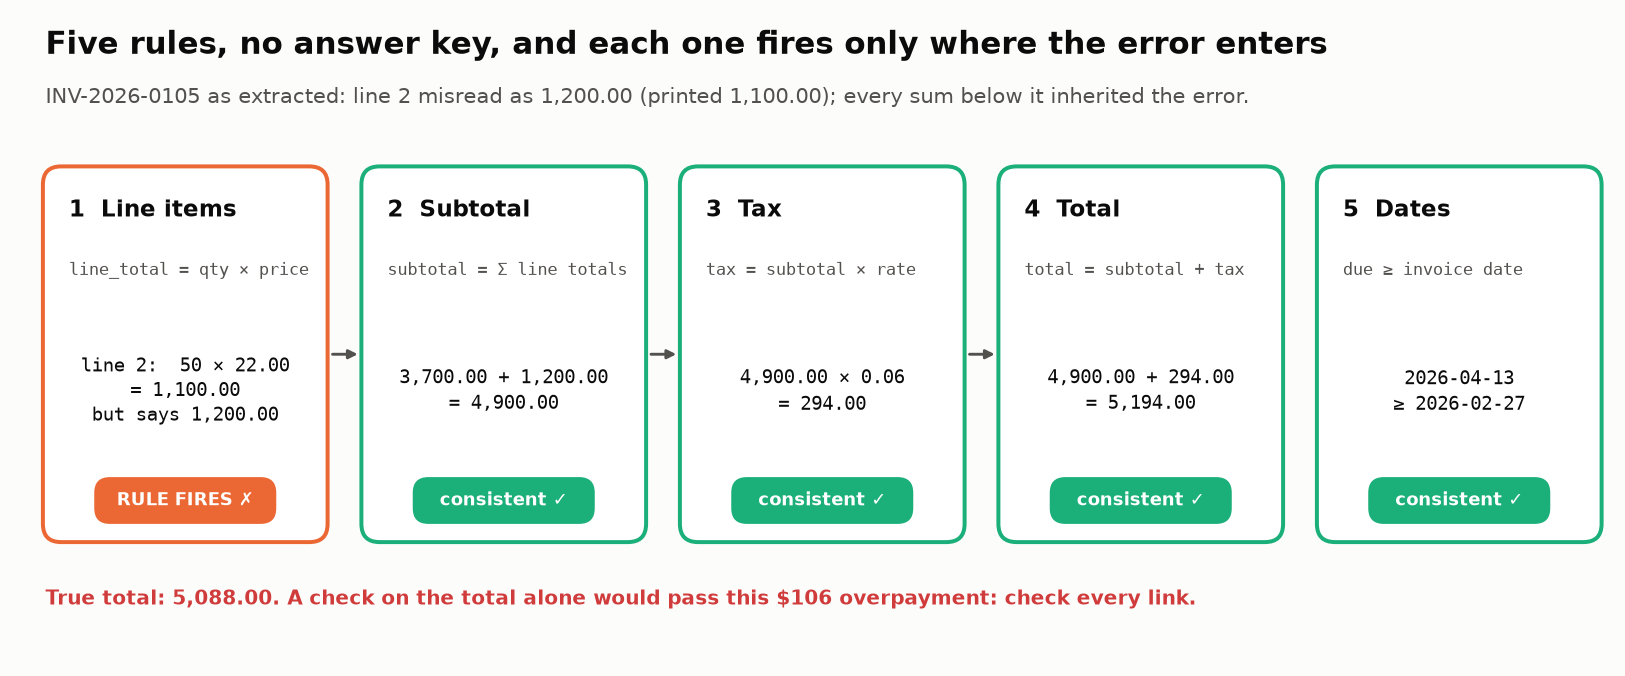

<sub>🖼️ *The five rules run on INV-2026-0105: each fires only where the error enters.*</sub>

🔍 **What just happened:** INV-2026-0105's error entered at line 2, and the subtotal, tax and total inherited it, so only the line-item rule fires. <mark>Check every relationship, not just the last one.</mark>

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** ⚠️ 0102 tax, 0105 line 2, 0106 dates, 0112 total, 0117 line 1. Tiles **10** · **0** · **5/10** · **0**. 0117 was caught only because the model *copied* the printed 540.00 (Challenge 1).
</details>

🗣️ **Say it to a colleague:** "Rules catch arithmetic for free; identity needs reference data. Route both to a human before posting."

🎛️ **Experiment:** a tolerance is a materiality policy. Drag `TRY_TOL`: at what slack does 0102's $27.57 tax error vanish? Would an auditor accept it?

In [ ]:
# 🎛️ Re-run the five rules with more slack, in dollars. 0 = one cent, the lab's TOL.
TRY_TOL = 0  # @param {type:"slider", min:0, max:150, step:5}

_saved, TOL = TOL, max(TRY_TOL, 0.01)
flagged_now = [iid[-4:] for iid, rec in outputs.items() if rule_check(rec)]
TOL = _saved
print(f"TOL = ${max(TRY_TOL, 0.01):,.2f} → flags {len(flagged_now)} of {len(broken)} broken invoices: {', '.join(flagged_now)}")

In [ ]:
# @title ❓ Quick check: rules missed INV-2026-0107, a Toronto vendor's CAD invoice booked as USD. What cheap check catches it with no labels?
answer = "— pick one —"  # @param ["— pick one —", "A) Look the vendor up in the vendor master: it bills in CAD", "B) A tighter tolerance on the totals", "C) Remove USD from the schema's enum", "D) Run the extraction twice and compare"]
quiz('Closing the identity gap', answer, correct="A",
     why="Identity errors are self-consistent, so arithmetic can't see them. Reference data accounts payable already holds (vendor master, PO register) can. Challenge 2 builds it.",
     wrong={"B": 'Every total is consistent; it is the money they are in that is wrong.',
          "C": 'Then every real USD invoice would fail.',
          "D": "A systematic misread repeats; agreement isn't correctness."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Rules catch arithmetic on every invoice; identity needs reference data.</b></font>

</td></tr></table>

---

## Task 9: 🧠 Your Turn: invariance tests (same invoice, new format, same JSON?) 🛡️

<big><b>A vendor changes a date format and your extractor changes a payment date, silently.</b></big>

> 🎯 **Goal:** re-render INV-2026-0107 in harmless formats and assert the extraction doesn't change.<br>
> ❓ **The question:** which format changes slip past every check?<br>
> 👀 **Watch for:** 🔇 silent breaks.

A deterministic **stand-in** reads the text in mock mode. Each **perturbation** changes format, not meaning:

| ✅ invariant | 🔊 loud break | 🔇 silent break |
|---|---|---|
| nothing changed | values changed, a check fired | values changed, <font color="#d03b3b"><b>⚠️ every check passed</b></font> |

In [ ]:
# @title 🔮 Predict: of 7 harmless format changes, how many change the JSON with no alarm?
silent_breaks_will_be = "— pick one —"  # @param ["— pick one —", "A) none: they are harmless", "B) 2", "C) 4", "D) all 7"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** extracts the clean document and 7 perturbations → read *outcome*.

In [ ]:
ROBUST_ID = "INV-2026-0107"
base = GOLD_FIXED[ROBUST_ID]
extract = standin_extract if PROVIDER == "mock" else extract_invoice

PERTURBATIONS = {
    "US dates (MM/DD/YYYY)": lambda inv: render_source(inv, date_style="us"),
    "Day-first dates (DD/MM/YYYY)": lambda inv: render_source(inv, date_style="dayfirst"),
    "No thousands separators": lambda inv: render_source(inv, thousands=False),
    "Decimal comma (1.276,90)": lambda inv: render_source(inv, decimal_comma=True),
    "Currency only as symbol (C$)": lambda inv: render_source(inv, currency_line=False),
    "Line items reversed": lambda inv: render_source(inv, reverse_items=True),
    "Vendor name in capitals": lambda inv: render_source(inv, vendor_upper=True),
}

canonical = extract(render_source(base))
baseline_ok = all(field_correct(f, canonical[f], base[f]) for f in FIELDS)
print(f"Baseline (clean document) matches gold: {baseline_ok}\n")

rows = []
for name, perturb in PERTURBATIONS.items():
    out = extract(perturb(base))
    changed = [f for f in FIELDS if not field_correct(f, out.get(f), canonical.get(f))]
    alarms = schema_errors(out) + (rule_check(out) if not schema_errors(out) else [])
    status = "✅ invariant" if not changed else ("🔊 loud break" if alarms else "🔇 silent break")
    rows.append({"perturbation": name, "outcome": status,
                 "changed fields": ", ".join(f"{f}: {canonical.get(f)!r}→{out.get(f)!r}" for f in changed
                                             if f != "line_items") + (" + line_items" if "line_items" in changed else ""),
                 "first alarm": alarms[0][:60] if alarms else ""})
robust = pd.DataFrame(rows)
display(robust)

▶️ **Run** (code hidden): tiles and a ⚠️ card.

In [ ]:
# @title 🧰 Tiles + card: loud vs silent breaks (hidden · 21 lines)
n_breaks = int((robust["outcome"] != "✅ invariant").sum())
n_silent = int((robust["outcome"] == "🔇 silent break").sum())
silent_names = list(robust.loc[robust["outcome"] == "🔇 silent break", "perturbation"])
tiles([
    ("Perturbations", len(robust), "meaning-preserving", None),
    ("Invariant", int((robust["outcome"] == "✅ invariant").sum()), "same JSON", "good"),
    ("Loud breaks", n_breaks - n_silent, "a check fired", "warning" if n_breaks - n_silent else "good"),
    ("Silent breaks", n_silent, "every check passed", "critical" if n_silent else "good"),
])
batch_echo = sorted(set(audit.loc[audit["field"].isin(["invoice_date", "currency"]), "invoice"]))
silent_changes = "; ".join(robust.loc[robust["outcome"] == "🔇 silent break", "changed fields"])
insight(
    f"{n_silent} of {n_breaks} breaking format changes were silent: schema-valid, rule-consistent and wrong",
    f"Silent: {'; '.join(silent_names)}. What changed: {silent_changes}. Nothing complained, because each wrong "
    f"value is well-typed and self-consistent. The real batch already contains both failure modes "
    f"({', '.join(batch_echo)}); with one example of each, no average could have "
    "warned you.\n"
    "**Rule of thumb:** keep an invariance test in your CI suite (continuous integration: the tests run on every code change) for every format your vendors use (locales, date orders, "
    "separators, symbols). Assert *same JSON*, not *valid JSON*.",
    kind="warning",
)

▶️ **Run:** grades your prediction.

In [ ]:
_p_silent = "A" if n_silent == 0 else "B" if n_silent <= 3 else "C" if n_silent < len(robust) else "D"
quiz("Your prediction: silent breaks", silent_breaks_will_be, correct=_p_silent,
     why=f"{n_silent} of {len(robust)}: {', '.join(silent_names)}. Each wrong value is well-typed and self-consistent, so nothing complains.")

> 📘 **Concept · Invariance test**
>
> **What it is:** render the same invoice in a harmless new format (day-first dates, no thousands separators, upper-case vendor) and assert the extraction does not change.
>
> **What it can't tell you:** whether the baseline is right; it compares two outputs with each other, so it needs no label and catches format sensitivity only.
>
> **Anchor:** day-first dates change `invoice_date` with no alarm: a silent break; a decimal comma trips a rule: a loud one.

✋ **Your turn:** find a silent break of your own.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _run_perturbation(fn):
    """(outcome, changed fields) for one perturbation of INV-2026-0107, scored like the table above."""
    out = extract(fn(base))
    changed = [f for f in FIELDS if not field_correct(f, out.get(f), canonical.get(f))]
    alarms = schema_errors(out) + (rule_check(out) if not schema_errors(out) else [])
    status = "✅ invariant" if not changed else ("🔊 loud break" if alarms else "🔇 silent break")
    return status, ", ".join(f"{f}: {canonical.get(f)!r}→{out.get(f)!r}" for f in changed)

In [ ]:
# ✋ Your turn: write a harmless format change that breaks the extraction SILENTLY.
#    It takes the invoice dict and returns the document text: start from render_source(inv) and edit the text.
my_perturbation = ...   # ✏️ e.g. lambda inv: render_source(inv).replace("TOTAL:", "TOTAL DUE:")

my_result = None
if not todo(my_perturbation):
    try:
        my_result, my_changed = _run_perturbation(my_perturbation)
        print(f"{my_result} · {my_changed or 'nothing changed'}")
    except Exception as e:
        my_result = f"{type(e).__name__}: {e}"
check("A silent break of your own", ... if todo(my_perturbation) else my_result, "🔇 silent break",
      hint="The example is loud: a missing total fails the schema. Make the extractor lose a field that is ALLOWED to be null.",
      success="Schema-valid, rule-consistent, wrong: a renamed label turned a printed value into a legal null. Only an invariance test notices.")

🔬 **Why the day-first swap survives testing:** test all of 2026, not one invoice.

<!-- img: swap-days.png -->
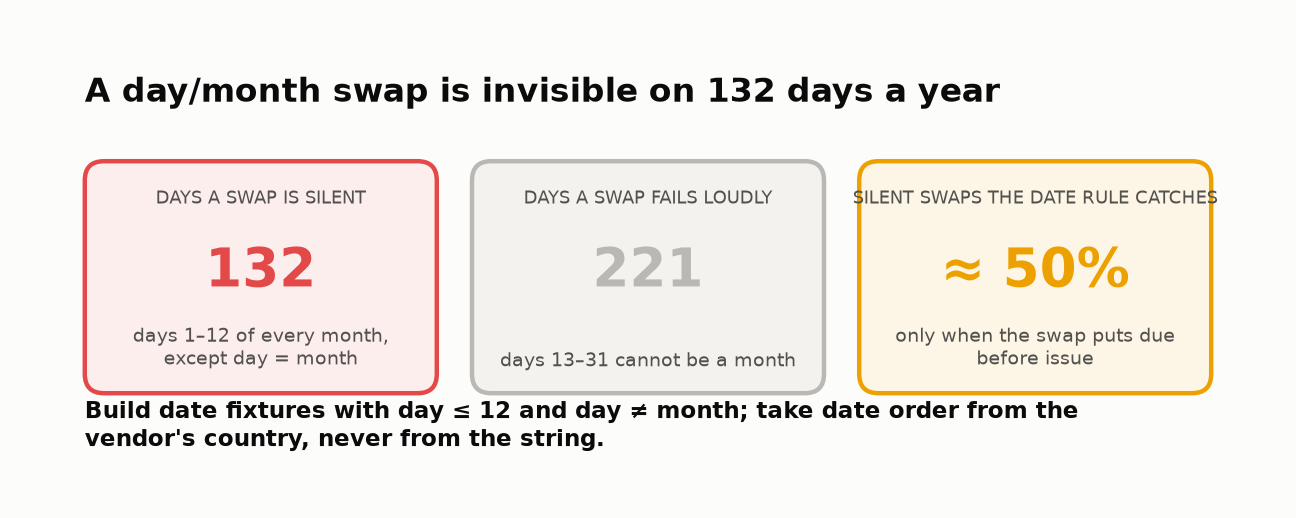
<sub>🖼️ *Run the next cells to compute these from the 2026 calendar.*</sub>

▶️ **Run:** every 2026 date written day-first, read month-first; does `due ≥ issue` notice?

In [ ]:
# 🔬 Every 2026 date written day-first (DD/MM/YYYY), then read month-first, as the stand-in (and many parsers) do
year = [date(2026, 1, 1) + timedelta(days=k) for k in range(365)]


def misread(d):
    try:
        return datetime.strptime(d.strftime("%d/%m/%Y"), "%m/%d/%Y").date()
    except ValueError:        # day 13-31 can't be a month: the parse fails loudly
        return None


swap = {d: "same" if misread(d) == d else "loud" if misread(d) is None else "silent" for d in year}
n_same, n_loud, n_silent_days = (sum(v == k for v in swap.values()) for k in ("same", "loud", "silent"))

# Net 30 invoices where both dates parse but at least one changed: does Task 8's date rule notice?
net30 = [(d, d + timedelta(days=30)) for d in year]
silent_pairs = [(d, due) for d, due in net30 if misread(d) and misread(due) and (misread(d), misread(due)) != (d, due)]
rule_hits = [(d, due) for d, due in silent_pairs if misread(due) < misread(d)]

▶️ **Run** (code hidden): the calendar grid.

In [ ]:
# @title 📊 The 2026 calendar grid (hidden · 16 lines · expand if curious)
fig, ax = plt.subplots(figsize=(11, 3.4))
colors = {"same": PALETTE[2], "silent": PALETTE[1], "loud": "#d9d8d4"}
for d, kind in swap.items():
    ax.add_patch(plt.Rectangle((d.day - 1, d.month - 1), 0.9, 0.85, color=colors[kind]))
ax.set_xlim(0, 31); ax.set_ylim(12, 0)
ax.set_xticks([i + 0.45 for i in range(31)], [str(i + 1) for i in range(31)], fontsize=8)
ax.set_yticks([i + 0.42 for i in range(12)], [date(2026, m, 1).strftime("%b") for m in range(1, 13)], fontsize=8.5)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel(f"day of month · orange = silently wrong ({n_silent_days}) · gray = parse fails loudly ({n_loud}) · "
              f"green = unchanged, day = month ({n_same})")
ax.set_title(f"A day/month swap is silent on {n_silent_days} of 365 days: exactly the days 1–12")
plt.tight_layout()
plt.show()

▶️ **Run** (code hidden): the counts and a 🤯 card.

In [ ]:
# @title 🧰 Counts + card: silent swaps vs the date rule (hidden · 14 lines)
print(f"Day-first dates in 2026: {n_same} unchanged · {n_silent_days} silently wrong · {n_loud} fail loudly")
print(f"Net 30 invoices whose dates swap silently: {len(silent_pairs)}; caught by due ≥ issue: "
      f"{len(rule_hits)} ({len(rule_hits) / len(silent_pairs):.0%})")
insight(
    f"The swap hides on the {n_silent_days} ambiguous days ({n_silent_days / 365:.0%} of the year), and the date "
    f"rule catches only {len(rule_hits) / len(silent_pairs):.0%} of those",
    f"On days 13–31 a month-first parser crashes ({n_loud} days), so a test set built from dates like 25/03 only "
    "ever sees the loud failure. On days 1–12 the result is a real date, just the wrong one. INV-2026-0106 was "
    "caught only because its swap put the due date before the issue date; across every Net 30 invoice of 2026, "
    f"`due ≥ issue` fires on {len(rule_hits)} of {len(silent_pairs)} silent swaps: a coin flip.\n"
    "**Rule of thumb:** build date fixtures with day ≤ 12 and day ≠ month, and take date order from the vendor's "
    "country, never from the string.",
    kind="surprise",
)

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** 🔇 day-first dates, `C$` only; 🔊 decimal comma. Calendar: **132** silent days; the date rule catches **49%**.
</details>

🗣️ **Say it to a colleague:** "Assert *same JSON*, not *valid JSON*. And build date fixtures with day ≤ 12, or you'll only ever see the loud failure."

In [ ]:
# @title ❓ Quick check: your date fixtures all use days 13–28. What will a day-first test show?
answer = "— pick one —"  # @param ["— pick one —", "A) The silent swap, on every fixture", "B) No failures: the parser handles both orders", "C) Half silent, half loud", "D) Only loud parse failures: a silent swap needs day ≤ 12"]
quiz('Date fixtures', answer, correct="D",
     why="Days 13–31 cannot be a month, so a month-first parse fails loudly. Days 1–12 make a real, wrong date, and only those hide. Build fixtures with day ≤ 12 and day ≠ month.",
     wrong={"A": "Day 13 and later can't be read as a month: the parse fails loudly.",
          "B": 'The stand-in, like many parsers, reads month-first.',
          "C": 'None of days 13–28 is ambiguous.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Assert the same JSON across formats, not just valid JSON; test dates with day ≤ 12.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 3 of 3 (Task 10): turn six checks into one decision, priced.

## Task 10: Go / no-go, with the uncertainty attached 🚦

<big><b>BLOCK costs money and so does SHIP; the gates say which, with the uncertainty attached.</b></big>

> 🎯 **Goal:** a SHIP / SHIP WITH CAUTION / BLOCK call from **release gates**: one pass/fail threshold per metric.<br>
> ❓ **The question:** can 20 audited invoices ever open a gate that needs a 90% lower bound?<br>
> 👀 **Watch for:** the critical-record gate's interval.

| Gate | Pass if |
|---|---|
| Schema validity | = 100% |
| Critical-record accuracy | ≥ 95%, and CI lower bound ≥ 90% |
| Hallucination rate | ≤ 2% |
| Silent invariance breaks | 0 |

**The weakest gate decides:** an average would let a perfect schema hide a 35% critical-error rate.

▶️ **Run:** measures each gate → four tiles.

In [ ]:
crit_k, n = S2["crit_records"], S2["n"]
crit_lo, crit_hi = wilson(crit_k, n)
gates = [  # (gate, measured value, detail, target, passed?)
    ("Schema validity", f"{schema_rate:.0%}", f"{n_valid}/{len(outputs)}", "= 100%", schema_rate == 1.0),
    ("Critical-record accuracy", f"{crit_k / n:.0%}", f"95% CI {crit_lo:.0%}–{crit_hi:.0%}", "≥ 95%, CI low ≥ 90%",
     crit_k / n >= 0.95 and crit_lo >= 0.90),
    ("Hallucination rate", f"{hall_rate2:.0%}", f"{n_hall2}/{gold_empty2} empty fields", "≤ 2%", hall_rate2 <= 0.02),
    ("Silent invariance breaks", str(n_silent), f"of {len(robust)} perturbations", "0", n_silent == 0),
]
tiles([(name, value, f"{detail} · gate {target}", "good" if ok else "critical") for name, value, detail, target, ok in gates])

failed = [g for g in gates if not g[4]]
only_ci_short = len(failed) == 1 and failed[0][0] == "Critical-record accuracy" and crit_k / n >= 0.95
decision = "SHIP" if not failed else ("SHIP WITH CAUTION" if only_ci_short else "BLOCK")

✋ **Your turn:** how big must the audit be for this gate to *ever* pass?

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_n = next(k for k in range(1, 500) if wilson(k, k)[0] >= 0.90)

In [ ]:
# ✋ Your turn: even a PERFECT audit (every invoice right) carries uncertainty.
print(f"Perfect 20/20 → 95% Wilson interval {wilson(20, 20)[0]:.0%}–{wilson(20, 20)[1]:.0%}")

my_min_audit = ...   # ✏️ the smallest n where a perfect n-of-n run has wilson(n, n)[0] >= 0.90

check("Smallest audit that can pass", my_min_audit, _ref_n,
      hint="Try wilson(30, 30)[0], wilson(40, 40)[0], … or write next(n for n in range(1, 500) if …).",
      success=f"{_ref_n} invoices. At n = 20 a perfect run's lower bound is {wilson(20, 20)[0]:.0%}: today's audit could never pass this gate, whatever the model did. Challenge 3 prices it properly.")

▶️ **Run:** the decision banner, with the fixes to make first.

In [ ]:
reasons = [f"**{name}: {value}** ({detail}; gate {target})" for name, value, detail, target, ok in failed]
reasons += [
    f"Schema validity was {schema_rate:.0%} throughout and predicted none of this.",
    "**Fix first:** locale-aware dates (vendor country decides DD/MM vs MM/DD) · currency from symbol + vendor country · "
    "vendor-master and PO lookups · prompt rule against computing due dates · route every business-rule violation to "
    "human review before posting.",
    f"**Then re-measure** on a larger, audited sample: with n = {n}, even a perfect run's 95% CI lower bound is only "
    f"{wilson(n, n)[0]:.0%}, so this gate cannot pass until you label at least {next(k for k in range(n, 500) if wilson(k, k)[0] >= 0.90)} invoices.",
]
verdict(decision, reasons)

<!-- img: gate-intervals.png -->
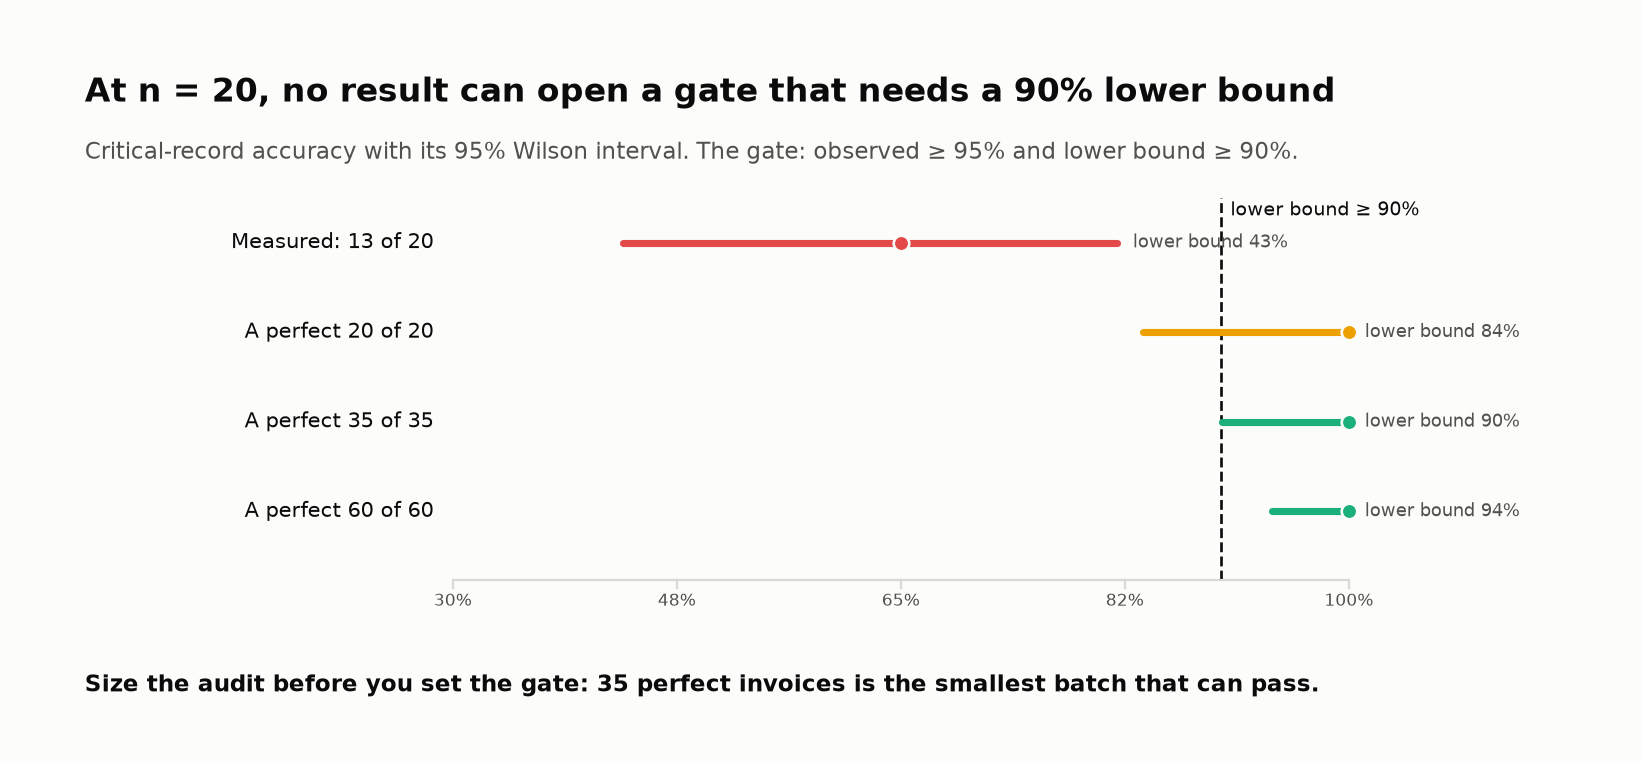
<sub>🖼️ *Challenge 3 asks how many invoices you must audit; this is why the answer is not 20.*</sub>

🔍 **What just happened:** the dashboard said "100% valid"; the gates say **BLOCK**, and the interval says this audit is too small to ever say SHIP.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Schema **100%** ✅ · critical **65%** ⛔ (CI 43%–82%) · hallucination **8%** ⛔ · silent **2** ⛔ → **🛑 BLOCK**.
</details>

💸 **What does each policy cost** until the fixes land? Costs are illustrative; whiskers are the Wilson range of the escape rate.

▶️ **Run** (code hidden): the simulator.

In [ ]:
# @title 🧰 Cost-of-errors simulator: the three policies and the chart function (hidden · 36 lines · expand if curious)
# 💸 Cost-of-errors simulator: what each operating policy costs per month (illustrative costs; set your own)
crit_wrong = set(scored_fixed.loc[scored_fixed["field"].isin(CRITICAL) & ~scored_fixed["correct"], "invoice"])
flagged = {i for i, issues in rule_results.items() if issues}
N_INV = len(outputs)
POLICIES = {  # policy -> (invoices a human reviews, invoices that escape with a wrong critical field)
    "Auto-post everything": (set(), crit_wrong),
    "Review rule-flagged invoices": (flagged, crit_wrong - flagged),
    "Review every invoice": (set(outputs), set()),
}


def show_policy_costs(volume=10_000, cost_error=150, cost_review=4.0):
    rows = []
    for name, (reviewed, escaped) in POLICIES.items():
        lo, hi = (0.0, 0.0) if len(reviewed) == N_INV else wilson(len(escaped), N_INV)  # full review: no escapes
        cost = lambda esc: volume * (len(reviewed) / N_INV * cost_review + esc * cost_error)
        rows.append((name, len(reviewed), len(escaped), cost(len(escaped) / N_INV), cost(lo), cost(hi)))
    best = min(rows, key=lambda r: r[3])[0]
    fig, ax = plt.subplots(figsize=(9, 2.6))
    for y, (name, n_rev, n_esc, c, c_lo, c_hi) in enumerate(rows[::-1]):
        ax.barh(y, c, color=PALETTE[2] if name == best else "#b9b8b3", height=0.55)
        ax.errorbar(c, y, xerr=[[c - c_lo], [c_hi - c]], fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
        ax.text(c_hi + max(r[5] for r in rows) * 0.02, y, f"${c:,.0f}", va="center", fontsize=10,
                weight="bold", parse_math=False)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
    ax.set_xlim(0, max(r[5] for r in rows) * 1.25)
    ax.xaxis.set_major_formatter(lambda x, _: f"${x / 1000:,.0f}k")
    ax.set_xlabel(f"cost per month at {volume:,} invoices · bars = 95% Wilson range of the escape rate (n = {N_INV})")
    ax.set_title(f"At ${cost_error:,g} per escaped error and ${cost_review:,g} per review, {best} is cheapest",
                 parse_math=False)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
    for name, n_rev, n_esc, c, _, _ in rows:
        print(f"{name}: {n_rev}/{N_INV} reviewed, {n_esc}/{N_INV} escape → ${c:,.0f} / month")

🎛️ **Experiment:** drag `COST_ERROR` down until *Review rule-flagged invoices* wins. Where does it flip? Does that survive the error bars?

In [ ]:
# 🎛️ Your assumptions. The defaults reproduce the lab's numbers; re-run after each drag.
VOLUME = 10000  # @param {type:"slider", min:1000, max:100000, step:1000}
COST_ERROR = 150  # @param {type:"slider", min:0, max:500, step:5}
COST_REVIEW = 4.0  # @param {type:"slider", min:0.5, max:20, step:0.5}

show_policy_costs(volume=VOLUME, cost_error=COST_ERROR, cost_review=COST_REVIEW)

▶️ **Run** (code hidden): where the cheapest policy flips, with its uncertainty.

In [ ]:
# @title 🧰 Card: the break-even between policies (hidden · 14 lines)
e_k, r_flag = len(crit_wrong - flagged), len(flagged) / N_INV
if e_k:
    e_lo, e_hi = wilson(e_k, N_INV)
    be, be_lo, be_hi = (1 - r_flag) / (e_k / N_INV), (1 - r_flag) / e_hi, (1 - r_flag) / e_lo
    insight(
        f"Reviewing everything beats reviewing only rule-flagged invoices once an escaped error costs more than "
        f"{be:.1f} reviews",
        f"Rule-flagged review sends {len(flagged)} of {N_INV} invoices to a human and still lets {e_k} through with a "
        f"wrong critical field ({', '.join(sorted(i[-4:] for i in crit_wrong - flagged))}): the identity errors no rule "
        f"sees. And {e_k}/{N_INV} is a 20-invoice rate: its 95% range is {e_lo:.0%}–{e_hi:.0%}, so the break-even is "
        f"anywhere from {be_lo:.1f}× to {be_hi:.0f}× the cost of a review.\n"
        "**Rule of thumb:** price the escapes, not the accuracy, and check that your policy choice survives the whole "
        "error bar before you commit to it.",
    )

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Auto-post **＄525,000**, rule-flagged **＄160,000**, review all **＄40,000** a month. Flips near `COST_ERROR = 30` (7.5 reviews).
</details>

🗣️ **Say it to a colleague:** "Price the escapes, not the accuracy. And at n = 20, no result can open a gate that needs a 90% lower bound."

In [ ]:
# @title ❓ Quick check: the gates say BLOCK, but invoices keep arriving. At 150 dollars per escaped error and 4 per review, what do you run until the fixes land?
answer = "— pick one —"  # @param ["— pick one —", "A) Auto-post everything and fix errors later", "B) Review only the rule-flagged invoices", "C) Review every invoice: cheapest, and nothing escapes", "D) Stop accepting invoices"]
quiz('What to run meanwhile', answer, correct="C",
     why=f"Rule-flagged review still lets {len(crit_wrong - flagged)} of {N_INV} critical errors through: the identity errors no rule sees. Each costs more than 7.5 reviews, so full review wins until the fixes land.",
     wrong={"A": 'About a third of invoices would post with a wrong critical field.',
          "B": 'Rules miss the identity errors (currency, payee, PO), the costly ones.',
          "D": "BLOCK means don't ship the new version, not stop the business."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Price the escapes, not the accuracy, and carry the interval into the decision.</b></font>

</td></tr></table>

✍️ **Your call** (double-click to edit): what would you monitor on all production traffic, and what would you sample for labelling weekly? *Your answer…*

---

## ✅ Validation or Success Criteria

<details><summary>Check yourself</summary>

- [ ] `scoreboard()` is green, or you know why
- [ ] Your BLOCK call cites gates, numbers and a policy
</details>

## 🛠️ Troubleshooting

<details><summary>Common problems</summary>

| Symptom | Fix |
|---|---|
| `NameError` | **Runtime → Run all** (the 🧰 catch-up rebuilds Part 1) |
| Every number differs | `PROVIDER = "mock"` |
</details>

## 🚀 Stretch Goal or Extension

<details><summary>Two extensions</summary>

1. **Locale rule:** take DD/MM vs MM/DD from the vendor's country; does 0106 resolve?
2. **CI:** fail the build on any schema error, rule violation or silent break.
</details>

### 🏆 Challenge exercises

Each starter runs as shipped and prints ✅/❌; solutions are in the instructor guide.

#### 🌶️ Challenge 1: Forge a perfect-looking wrong invoice

**Stakes:** this is the invoice that gets paid, because every automatic check said yes.

Edit `forged` (INV-2026-0101) so it is schema-valid, passes all five rules, and pays **≥ $100** too much or too little. Which check still catches it?

<details><summary>💡 Hint</summary>

Change one `quantity`, then recompute every sum below it the way `_invoice()` does. What does `supported()` need?
</details>

▶️ **Run:** checks your forgery.

In [ ]:
# 🌶️ CHALLENGE 1: every label-free check in Tasks 3 and 8 accepts it, yet it pays the wrong amount.
truth = GOLD_FIXED["INV-2026-0101"]
forged = deepcopy(truth)
# TODO: edit `forged` here, e.g. forged["line_items"][0]["quantity"] = ..., and keep every rule satisfied.

c1 = {"schema-valid (Task 3)": not schema_errors(forged)}
c1["passes all business rules (Task 8)"] = c1["schema-valid (Task 3)"] and not rule_check(forged)
c1["total off by ≥ $100"] = abs(forged["total_amount"] - truth["total_amount"]) >= 100
for name, ok in c1.items():
    print(f"{'✅' if ok else '❌'} {name}")
if all(c1.values()):
    ungrounded = [f for f in FIELDS if not supported(f, forged[f], SOURCES["INV-2026-0101"])]
    print(f"\n🔎 But supported() finds these values nowhere in the source: {ungrounded}")
    print("   supported() needs the document, not a gold label: it can run on every invoice in production.")
else:
    print("\n📝 Not forged yet: all three checks must show ✅.")


#### 🌶️🌶️ Challenge 2: Close the identity gap

**Stakes:** the five invoices the rules missed are the ones that pay the wrong vendor in the wrong currency.

Write `identity_issues(rec)` from the vendor master and PO register alone: catch **≥ 4 of the 5** misses with **0** false alarms.

<details><summary>💡 Hint</summary>

Compare names with `norm_name()`. One miss breaks a `payment_terms` ↔ `due_date` rule Task 8 never wrote.
</details>

▶️ **Run:** scores your `identity_issues()`.

In [ ]:
# 🌶️🌶️ CHALLENGE 2: catch Task 8's misses with zero gold labels, using reference data AP already has.
VENDOR_MASTER = {r["vendor_name"]: r["currency"] for r in _TRUTH.values()}   # approved vendor → billing currency
PO_REGISTER = {r["po_number"]: r["vendor_name"] for r in _TRUTH.values() if r["po_number"]}  # PO → vendor


def identity_issues(rec) -> list[str]:
    """Problems visible from the record plus reference data alone (empty list = looks fine)."""
    issues = []
    # TODO 1: vendor_name is not in VENDOR_MASTER (compare with norm_name)
    # TODO 2: currency differs from the vendor's billing currency
    # TODO 3: po_number is set, but PO_REGISTER doesn't have it or issued it to another vendor
    # TODO 4: a payment-terms rule: what must due_date be when terms are "Due on receipt"?
    return issues


c2 = {iid: identity_issues(rec) for iid, rec in outputs.items()}
clean = [i for i in outputs if i not in broken]
caught2, false2 = [i for i in missed if c2[i]], [i for i in clean if c2[i]]
print(f"Task 8 misses caught: {len(caught2)}/{len(missed)} ({', '.join(i[-4:] for i in caught2) or 'none yet'})")
print(f"False alarms on the {len(clean)} correct invoices: {len(false2)} ({', '.join(i[-4:] for i in false2) or 'none'})")
print("✅ Identity gap closed" if len(caught2) >= 4 and not false2 else
      "❌ Target: catch at least 4 of the 5 misses with 0 false alarms")


#### 🌶️🌶️🌶️ Challenge 3: How many invoices must you audit to ship?

**Stakes:** an audit too small to pass its own gate blocks a good model forever; one too large burns the labelling budget.

True critical-record accuracy is **97%**; the gate needs ≥ 95% observed *and* a Wilson lower bound ≥ 90%. Write `p_pass(p, n)` (binomial), then find `n_typical` and `n_80`. Why is the curve a sawtooth?

<details><summary>💡 Hint</summary>

Sum `comb(n, k) * p**k * (1 - p)**(n - k)` over the k where `gate_passes(k, n)`.
</details>

▶️ **Run** (code hidden; spoiler): the checker's reference. Then run your attempt.

In [ ]:
# @title 🔒 Reference for Challenge 3's checker (hidden · spoiler)
def _reference_challenge3(p):
    from math import comb
    ok = lambda k, n: k / n >= 0.95 and wilson(k, n)[0] >= 0.90
    pp = lambda n: sum(comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(n + 1) if ok(k, n))
    n_typ = next(n for n in range(1, 2000) if ok(round(p * n), n))
    return {"n_typical": n_typ, "p_typical": pp(n_typ), "n_80": next(n for n in range(1, 2000) if pp(n) >= 0.80)}

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: audit size, as a probability rather than a guess.
from math import comb

TRUE_RATE = 0.97


def gate_passes(k, n):
    """Task 10's critical-record gate for k fully-critical-correct invoices out of n."""
    return k / n >= 0.95 and wilson(k, n)[0] >= 0.90


def p_pass(p, n):
    """P(the gate passes) for a model whose true rate is p, audited on n invoices."""
    return None   # TODO: sum the binomial probabilities of every k with gate_passes(k, n)


n_typical = None  # TODO: smallest n where gate_passes(round(TRUE_RATE * n), n)
n_80 = None       # TODO: smallest n where p_pass(TRUE_RATE, n) >= 0.80

ref3 = _reference_challenge3(TRUE_RATE)
if p_pass(TRUE_RATE, 50) is None or n_typical is None or n_80 is None:
    print("📝 TODO: implement p_pass, then set n_typical and n_80.")
else:
    p_typ = p_pass(TRUE_RATE, ref3["n_typical"])
    print(f"{'✅' if n_typical == ref3['n_typical'] else '❌'} n_typical = {n_typical}")
    print(f"{'✅' if abs(p_typ - ref3['p_typical']) < 1e-9 else '❌'} P(pass) at n = {ref3['n_typical']}: {p_typ:.1%}")
    print(f"{'✅' if n_80 == ref3['n_80'] else '❌'} n_80 = {n_80}")
    ns = list(range(20, 201))
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(ns, [p_pass(TRUE_RATE, k) for k in ns], color=PALETTE[0])
    ax.axhline(0.8, color="#b9b8b3", lw=1, ls="--")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("invoices audited (n)"); ax.set_ylabel("P(gate passes)")
    ax.set_title("TODO: write the takeaway as the title")
    plt.tight_layout(); plt.show()


#### 🌶️🌶️ Challenge 4: Paid twice (🏦 accounts-payable variant)

**Stakes:** every check in this lab looks at one record at a time. The most expensive extraction error in accounts payable is paying the same invoice twice, and no per-record check can see it.

INV-2026-0121 re-issues 0113 two days later; INV-2026-0122 is CloudServ's legitimate April bill. Finish `find_duplicates()` and set `WINDOW_DAYS` so exactly one pair is flagged. Who in finance owns that window?

<details><summary>💡 Hint</summary>

Same `norm_name`, `same_cents` total, and a day gap under the window: 2 days is a re-issue, 31 a billing cycle.
</details>

▶️ **Run:** both records pass every check; then your finder is scored.

In [ ]:
# ============================================================================
# 🌶️🌶️ CHALLENGE 4: paid twice (runs as shipped; finish the TODO and set WINDOW_DAYS)
# ============================================================================
WINDOW_DAYS = None     # 👈 (2) same vendor + same total within this many days = a resubmission, not a recurring charge

resubmitted = deepcopy(outputs["INV-2026-0113"])         # the vendor re-issued the invoice with a new number
resubmitted.update(invoice_number="INV-2026-0121", invoice_date="2026-03-20", due_date="2026-04-19",
                   vendor_name="SUMMIT OFFICE FURNITURE")
recurring = deepcopy(outputs["INV-2026-0111"])           # CloudServ Pro bills the same amount every month
recurring.update(invoice_number="INV-2026-0122", invoice_date="2026-04-01", due_date="2026-05-01")
batch_plus = {**outputs, "INV-2026-0121": resubmitted, "INV-2026-0122": recurring}

for iid in ("INV-2026-0121", "INV-2026-0122"):
    alarms = schema_errors(batch_plus[iid]) or rule_check(batch_plus[iid])
    print(f"{iid}: {'✅ passes the schema and every business rule' if not alarms else alarms}")


def find_duplicates(batch):
    """Pairs of invoice ids that look like one invoice submitted twice."""
    pairs = set()
    if WINDOW_DAYS is None:
        return pairs
    recs = list(batch.items())
    for k, (ia, a) in enumerate(recs):
        for ib, b in recs[k + 1:]:
            looks_duplicate = False   # TODO (1): same vendor (norm_name), same total (same_cents), dates within WINDOW_DAYS
            if looks_duplicate:
                pairs.add(frozenset({ia, ib}))
    return pairs


EXPECTED = {frozenset({"INV-2026-0113", "INV-2026-0121"})}
found = find_duplicates(batch_plus)
hit_recurring = any("INV-2026-0122" in p for p in found)
print("✅" if found == EXPECTED else "❌",
      f"{len(found)} pair(s) flagged · re-issue {'caught' if EXPECTED <= found else 'missed'} · "
      f"recurring CloudServ charge {'wrongly flagged' if hit_recurring else 'left alone'}")

#### 🌶️🌶️🌶️ Challenge 5: Your batch is not your traffic

**Stakes:** next quarter the product launches in Canada. The eval batch is 90% USD invoices; production will be 60%. A number measured on the wrong mix is a number about a different product.

🔮 Projected onto `PRODUCTION_MIX`, does critical-record accuracy land **A)** within 5 points, **B)** 5–15 lower or **C)** 15+ lower? Then set `PROJECTED_PCT` and `N_NON_USD` (labels for a ≤ 20-point interval at 70%).

<details><summary>💡 Hint</summary>

Two non-USD invoices, both wrong: their interval is 0%–66%. Scan n with `wilson(round(0.7 * n), n)`.
</details>

▶️ **Run:** segments, projection and your two answers.

In [ ]:
# ============================================================================
# 🌶️🌶️🌶️ CHALLENGE 5: your batch is not your traffic (runs as shipped; fill in the two 👈 values)
# ============================================================================
PRODUCTION_MIX = {"USD": 0.60, "CAD": 0.25, "GBP": 0.10, "EUR": 0.05}   # next quarter's invoice mix
PROJECTED_PCT = None      # 👈 (2) critical-record accuracy projected onto PRODUCTION_MIX, in %
N_NON_USD = None          # 👈 (3) non-USD invoices to label for a 95% CI ≤ 20 points wide at a 70% rate

crit_ok = scored_fixed[scored_fixed["field"].isin(CRITICAL)].groupby("invoice")["correct"].all()
seg = (pd.DataFrame({"currency": [GOLD_FIXED[i]["currency"] for i in crit_ok.index], "ok": crit_ok.values})
       .groupby("currency")["ok"].agg(n="size", k="sum"))
seg["rate"] = seg["k"] / seg["n"]
seg["95% CI"] = [f"{lo:.0%}–{hi:.0%}" for lo, hi in (wilson(int(k), int(n)) for k, n in zip(seg["k"], seg["n"]))]
display(seg)

non_usd = seg.drop("USD", errors="ignore")
pooled_non_usd = non_usd["k"].sum() / non_usd["n"].sum()          # segments missing from the batch borrow this
rate_of = lambda c: seg.loc[c, "rate"] if c in seg.index else pooled_non_usd
projected = sum(w * rate_of(c) for c, w in PRODUCTION_MIX.items())
batch_rate = seg["k"].sum() / seg["n"].sum()
nu_lo, nu_hi = wilson(int(non_usd["k"].sum()), int(non_usd["n"].sum()))
tiles([
    ("Batch critical-record accuracy", f"{batch_rate:.0%}", f"{int(seg['k'].sum())}/{int(seg['n'].sum())} · {seg.loc['USD', 'n'] / seg['n'].sum():.0%} USD", "warning"),
    ("Projected at the production mix", f"{projected:.0%}", f"{PRODUCTION_MIX['USD']:.0%} USD", "critical"),
    ("Non-USD evidence", f"{int(non_usd['k'].sum())}/{int(non_usd['n'].sum())}", f"95% CI {nu_lo:.0%}–{nu_hi:.0%}", "critical"),
])


def ci_width(n, p=0.7):
    lo, hi = wilson(round(p * n), n)
    return hi - lo


n_needed = next(n for n in range(5, 5000) if ci_width(n) <= 0.20)
ok2 = PROJECTED_PCT is not None and abs(PROJECTED_PCT - 100 * projected) <= 3
ok3 = N_NON_USD is not None and abs(N_NON_USD - n_needed) <= max(5, 0.1 * n_needed)
print("✅" if ok2 else "❌", f"(2) projected critical-record accuracy at the production mix: {projected:.0%}"
      + ("" if PROJECTED_PCT is None else f" (you said {PROJECTED_PCT}%)"))
print("✅" if ok3 else "❌", f"(3) non-USD invoices to label for a ≤ 20-point interval at 70%: {n_needed}"
      + ("" if N_NON_USD is None else f" (you said {N_NON_USD})"))

---

## 🏁 Key Takeaways

**🔑 The five things to remember**

1. **Schema validity is solved:** a free 100% gate, not a quality metric.
2. **Field accuracy flatters; record accuracy tells the truth:** errors compound across fields.
3. **Absence is a value:** make "not found" representable; count hallucinations and omissions separately.
4. **Audit the answer key:** the source document decides who is wrong.
5. <font color="#2a78d6"><b>Label-free checks are your production net: rules catch arithmetic, invariance tests catch silent format breaks, reference data catches identity.</b></font>

### 📒 Insight Ledger

▶️ **Run:** your one-page summary, computed from this run.

In [ ]:
ledger = [
    ("3 Schema", f"{schema_rate:.0%} of strict outputs valid, incl. the wrong-tax invoice; legacy {n_legacy_valid}/{len(LEGACY_OUTPUTS)}",
     "Schema validity is a free pipeline-health gate, not a quality metric."),
    ("4 Weights", f"{len(CRITICAL)} critical fields carry {crit_share:.0%} of the weight",
     "Weight for the dashboard; gate on critical fields. Get weights from whoever absorbs the errors."),
    ("5 Accuracy", f"{S['field_acc']:.0%} of fields right, {S['full_records']}/{S['n']} records fully right ({S['field_acc']:.3f}^{len(FIELDS)} ≈ {independent:.0%})",
     "Always report record-level accuracy next to field accuracy."),
    ("6 Nulls", f"{n_hall} values invented for {gold_empty} empty fields; non-nullable schema → {len(unrepresentable)}/{len(GOLD)} correct answers unrepresentable",
     "Make 'not found' representable; measure hallucination and omission separately."),
    ("7 Gold audit", f"{n_label} of {len(audit)} 'model errors' were label errors; {n_amb} need a human",
     "Check the source before blaming the model; budget for re-labelling."),
    ("8 Rules", f"Caught {len(caught_by_rules)}/{len(broken)} broken invoices with no labels; misses were {', '.join(missed_fields)}",
     "Rules catch arithmetic; identity needs reference data (vendor master, PO, currency)."),
    ("9 Invariance", f"{n_silent} of {n_breaks} breaking format changes were silent; a day/month swap is silent on "
     f"{n_silent_days} of 365 days",
     "Assert same JSON across formats, not just valid JSON; test dates with day ≤ 12."),
    ("10 Decision", f"{decision}: critical-record accuracy {crit_k / n:.0%} (CI {crit_lo:.0%}–{crit_hi:.0%})",
     "The weakest gate decides, and small n needs a confidence interval."),
]
display(Markdown("| Task | What you saw | Rule of thumb |\n|---|---|---|\n" +
                 "\n".join(f"| {t} | {s} | {r} |" for t, s, r in ledger)))

▶️ **Run:** see which exercises and checks to revisit.

In [ ]:
scoreboard()

## 🔮 What's Next: Module 04, Evaluating RAG Systems

Same habits, new source: check each value against what was retrieved, separate "didn't find it" from "made it up", and audit the gold.

<!-- img: check-ladder.png -->
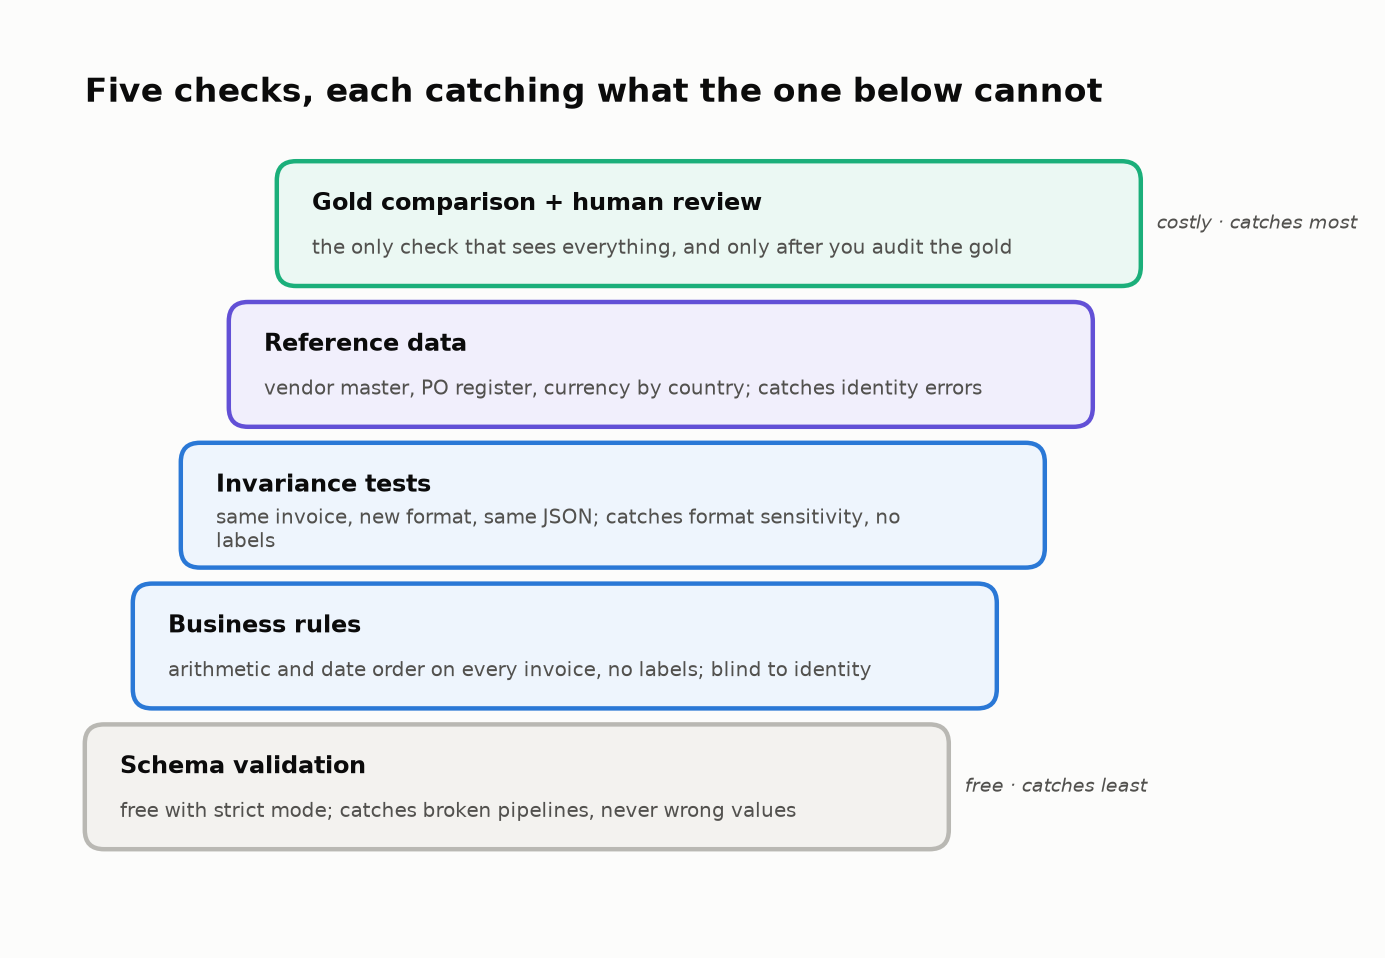
<sub>🖼️ *The lab's checks as a ladder: climb it in order, and stop reporting the bottom rung as quality.*</sub>